# Generation of Synthetic Dataset


## 1. imports


In [70]:

import pandas as pd
import matplotlib.pyplot as plt

## 2. Experimental Dataset sampling

Apple didn't exist until 1976 and didn't go public until 1980; Microsoft was founded in 1975 but only went public in 1986 — so there are no stock prices to sample in 1975 for either company. Even if pre-IPO valuations were somehow available, the companies were tiny partnerships with no resemblance to the tech giants whose post-IPO growth rates you'd be extrapolating backward. The inflation rate and the unemployment rate are a far better choice for a 1970–2025 simulation window, since both have been published continuously as monthly official statistics since the 1940s.

### 2.1 Real Apple TS

Lade Apple-Kursdaten aus lokalem Cache: ../data/stock_prices/AAPL_1970-01-01_2026-06-12.csv
Cache aktualisiert: ../data/stock_prices/AAPL_1970-01-01_2026-06-12.csv

                Apple (AAPL) Tageskurse 2012–2026                
          (split-bereinigt, via Yahoo Finance, in USD)           
Datum            Kurs (USD)   Veränd. (%)    Veränd. (USD)
-----------------------------------------------------------------
1980-12-12     $      0.10         —               —
1980-12-15     $      0.09       -5.22%       -$   0.01
1980-12-16     $      0.09       -7.34%       -$   0.01
1980-12-17     $      0.09     +  2.48%       +$   0.00
1980-12-18     $      0.09     +  2.90%       +$   0.00
1980-12-19     $      0.10     +  6.10%       +$   0.01
1980-12-22     $      0.10     +  4.87%       +$   0.00
1980-12-23     $      0.11     +  4.22%       +$   0.00
1980-12-24     $      0.11     +  5.26%       +$   0.01
1980-12-26     $      0.12     +  9.23%       +$   0.01
1980-12-29     $     

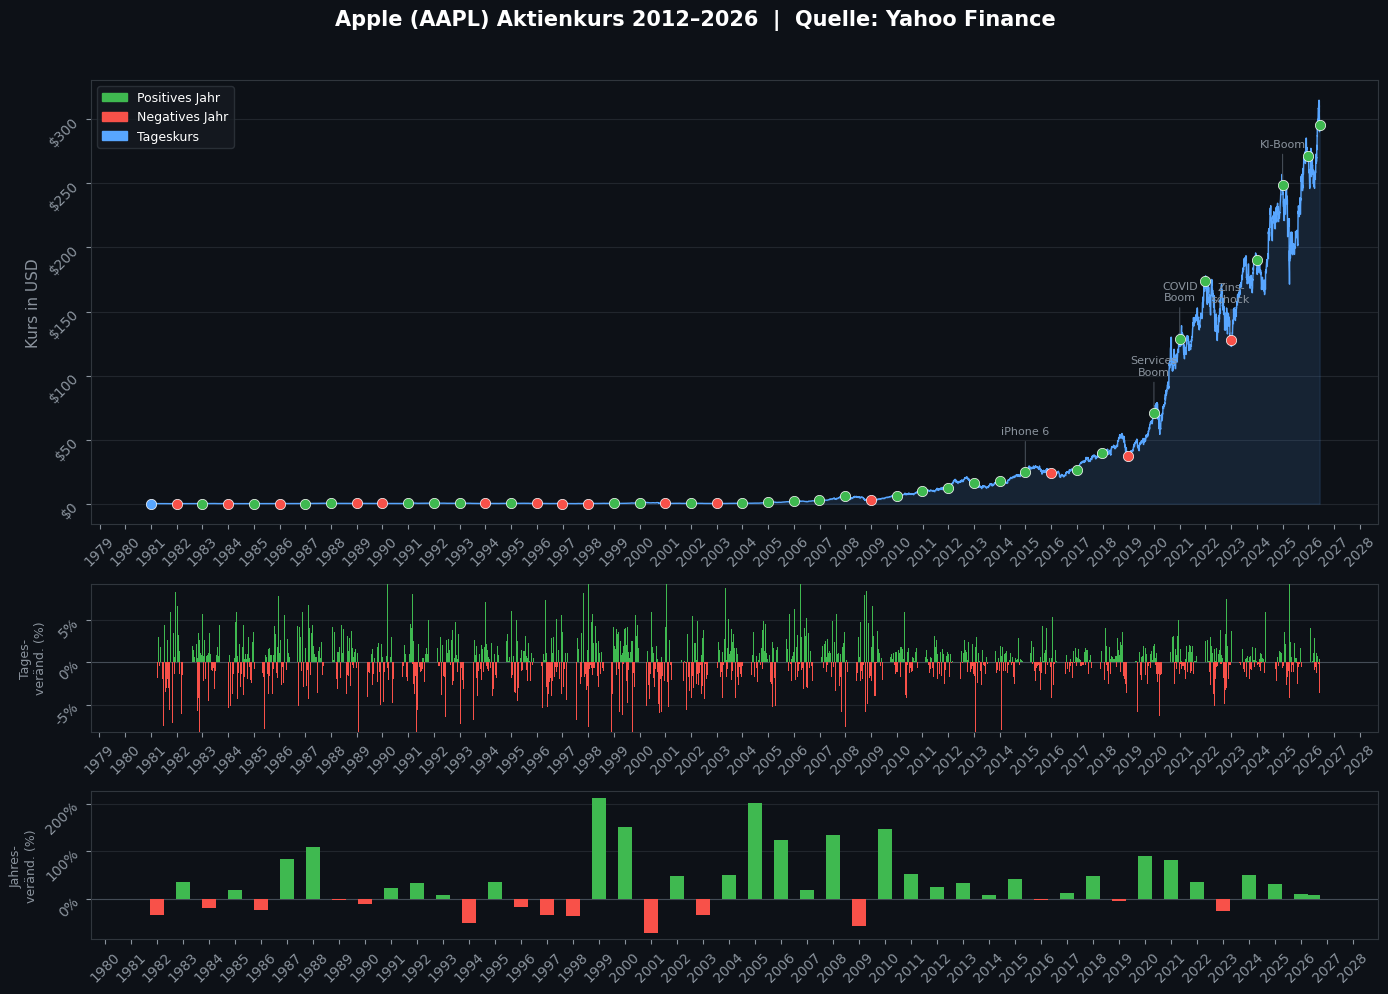

In [71]:
import os
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

# ── Konfiguration ─────────────────────────────────────────────────
TICKER = "AAPL"
START = "1970-01-01"
END = "2026-06-12"
DATA_DIR = "../data/stock_prices"
CACHE_FILE = os.path.join(DATA_DIR, f"{TICKER}_{START}_{END}.csv")

# ── Daten laden (aus Cache oder von Yahoo Finance) ─────────────────
os.makedirs(DATA_DIR, exist_ok=True)

if os.path.exists(CACHE_FILE):
    print(f"Lade Apple-Kursdaten aus lokalem Cache: {CACHE_FILE}")
    df = pd.read_csv(CACHE_FILE, index_col=0, parse_dates=True)
else:
    print("Lade Apple-Kursdaten von Yahoo Finance...")
    df = yf.download(TICKER, start=START, end=END, progress=False)
    df = df[["Close"]].copy()
    df.columns = ["Kurs"]
    df.index = df.index.tz_localize(None)
    df.to_csv(CACHE_FILE)
    print(f"Daten gespeichert unter: {CACHE_FILE}")

OUT_PATH = os.path.join(DATA_DIR, "baseline_all_commodities.csv")

# ── Immer speichern (aktualisierter Cache) ────────────────────────
df.to_csv(CACHE_FILE)
print(f"Cache aktualisiert: {CACHE_FILE}")

# Jahresschlusskurse
jahres = df.resample("YE").last()
jahres.index = jahres.index.year

# ── Tagesweise Konsolenausgabe ───────────────────────────────────
print("\n" + "=" * 65)
print(f"{'Apple (AAPL) Tageskurse 2012–2026':^65}")
print(f"{'(split-bereinigt, via Yahoo Finance, in USD)':^65}")
print("=" * 65)
print(f"{'Datum':<14} {'Kurs (USD)':>12}   {'Veränd. (%)':<14} {'Veränd. (USD)'}")
print("-" * 65)

prev = None
for datum, row in df.iterrows():
    kurs = row["Kurs"]
    if prev is None:
        pct_str, abs_str = "      —", "       —"
    else:
        pct = (kurs - prev) / prev * 100
        absd = kurs - prev
        pct_str = f"  +{pct:6.2f}%" if pct >= 0 else f"  {pct:7.2f}%"
        abs_str = f"  +${absd:7.2f}" if absd >= 0 else f"  -${abs(absd):7.2f}"
    print(f"{str(datum.date()):<14} ${kurs:>10.2f}   {pct_str:<14} {abs_str}")
    prev = kurs

print("-" * 65)
gesamt = (df["Kurs"].iloc[-1] - df["Kurs"].iloc[0]) / df["Kurs"].iloc[0] * 100
print(f"{'Gesamtrendite:':<35} +{gesamt:.0f}%")
print(f"{'Aus $1.000 wurden:':<35} ${1000 * df['Kurs'].iloc[-1] / df['Kurs'].iloc[0]:,.0f}")
print("=" * 65)

# ── Jahresübersicht ──────────────────────────────────────────────
kurse_list = jahres["Kurs"].tolist()
jahre_list = jahres.index.tolist()

print("\n" + "=" * 55)
print(f"{'Jahresübersicht':^55}")
print("=" * 55)
print(f"{'Jahr':<8} {'Kurs (USD)':>12}   {'Veränd. (%)':<14} {'Trend'}")
print("-" * 55)
for i, (jahr, kurs) in enumerate(zip(jahre_list, kurse_list)):
    if i == 0:
        pct_str, trend = "      —", ""
    else:
        pct = (kurs - kurse_list[i - 1]) / kurse_list[i - 1] * 100
        pct_str = f"  +{pct:6.2f}%" if pct >= 0 else f"  {pct:7.2f}%"
        trend = "▲" * min(int(abs(pct) / 15) + 1, 5) if pct >= 0 else "▼"
    hinweis = " ← aktuell" if i == len(jahre_list) - 1 else ""
    print(f"{jahr:<8} ${kurs:>10.2f}   {pct_str:<14} {trend}{hinweis}")
print("=" * 55)

# ── Grafik ───────────────────────────────────────────────────────
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10),
    gridspec_kw={"height_ratios": [3, 1, 1]},
    facecolor="#0d1117"
)
ax1, ax2, ax3 = axes
fig.suptitle(
    "Apple (AAPL) Aktienkurs 2012–2026  |  Quelle: Yahoo Finance",
    color="white", fontsize=15, fontweight="bold", y=0.99
)

# — ax1: Tageskurs-Linie —
ax1.set_facecolor("#0d1117")
ax1.plot(df.index, df["Kurs"], color="#58a6ff", linewidth=1.0, zorder=3)
ax1.fill_between(df.index, df["Kurs"], alpha=0.12, color="#58a6ff", zorder=2)

# Jahrespunkte einfärben
for i, (jahr, kurs) in enumerate(zip(jahre_list, kurse_list)):
    if i == 0:
        farbe = "#58a6ff"
    else:
        farbe = "#3fb950" if kurs >= kurse_list[i - 1] else "#f85149"
    datum = df[df.index.year == jahr].index[-1]
    ax1.scatter(datum, kurs, color=farbe, s=55, zorder=4,
                edgecolors="white", linewidths=0.5)

# Ereignis-Annotationen
ereignisse = {
    2014: "iPhone 6",
    2019: "Services\nBoom",
    2020: "COVID\nBoom",
    2022: "Zins-\nschock",
    2024: "KI-Boom",
}
for jahr, label in ereignisse.items():
    if jahr in jahres.index:
        kurs = jahres.loc[jahr, "Kurs"]
        datum = df[df.index.year == jahr].index[-1]
        ax1.annotate(
            label, xy=(datum, kurs), xytext=(datum, kurs + 30),
            fontsize=8, color="#8b949e", ha="center",
            arrowprops=dict(arrowstyle="-", color="#444c56", lw=0.8),
        )

ax1.set_ylabel("Kurs in USD", color="#8b949e", fontsize=11)
ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0f"))
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.tick_params(colors="#8b949e", rotation=45)
for spine in ax1.spines.values():
    spine.set_edgecolor("#30363d")
ax1.grid(axis="y", color="#21262d", linewidth=0.8)
ax1.set_axisbelow(True)

# — ax2: tägliche Veränderung in % —
ax2.set_facecolor("#0d1117")
tages_pct = df["Kurs"].pct_change() * 100
farben_tag = ["#3fb950" if v >= 0 else "#f85149" for v in tages_pct]
ax2.bar(df.index, tages_pct, color=farben_tag, width=1.5, zorder=3)
ax2.axhline(0, color="#444c56", linewidth=0.8)
ax2.set_ylabel("Tages-\nveränd. (%)", color="#8b949e", fontsize=9)
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax2.set_ylim(tages_pct.quantile(0.005), tages_pct.quantile(0.995))
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.tick_params(colors="#8b949e", rotation=45)
for spine in ax2.spines.values():
    spine.set_edgecolor("#30363d")
ax2.grid(axis="y", color="#21262d", linewidth=0.8)
ax2.set_axisbelow(True)

# — ax3: jährliche Veränderung —
ax3.set_facecolor("#0d1117")
farben_j, werte_j, pos_j = [], [], []
for i in range(1, len(jahre_list)):
    pct = (kurse_list[i] - kurse_list[i - 1]) / kurse_list[i - 1] * 100
    datum = df[df.index.year == jahre_list[i]].index[-1]
    pos_j.append(datum)
    werte_j.append(pct)
    farben_j.append("#3fb950" if pct >= 0 else "#f85149")

ax3.bar(pos_j, werte_j, color=farben_j, width=200, zorder=3)
ax3.axhline(0, color="#444c56", linewidth=0.8)
ax3.set_ylabel("Jahres-\nveränd. (%)", color="#8b949e", fontsize=9)
ax3.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax3.tick_params(colors="#8b949e", rotation=45)
for spine in ax3.spines.values():
    spine.set_edgecolor("#30363d")
ax3.grid(axis="y", color="#21262d", linewidth=0.8)
ax3.set_axisbelow(True)

# Legende
from matplotlib.patches import Patch
ax1.legend(
    handles=[
        Patch(color="#3fb950", label="Positives Jahr"),
        Patch(color="#f85149", label="Negatives Jahr"),
        Patch(color="#58a6ff", label="Tageskurs"),
    ],
    loc="upper left", facecolor="#161b22",
    edgecolor="#30363d", labelcolor="white", fontsize=9
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Lade Apple-Kursdaten aus lokalem Cache: ../data/stock_prices/AAPL_1970-01-01_2025-12-31.csv

                Apple (AAPL) Tageskurse 2012–2026                
          (split-bereinigt, via Yahoo Finance, in USD)           
Datum            Kurs (USD)   Veränd. (%)    Veränd. (USD)
-----------------------------------------------------------------
1980-12-12     $      0.10         —               —
1980-12-15     $      0.09       -5.22%       -$   0.01
1980-12-16     $      0.09       -7.34%       -$   0.01
1980-12-17     $      0.09     +  2.48%       +$   0.00
1980-12-18     $      0.09     +  2.90%       +$   0.00
1980-12-19     $      0.10     +  6.10%       +$   0.01
1980-12-22     $      0.10     +  4.87%       +$   0.00
1980-12-23     $      0.11     +  4.22%       +$   0.00
1980-12-24     $      0.11     +  5.26%       +$   0.01
1980-12-26     $      0.12     +  9.23%       +$   0.01
1980-12-29     $      0.12     +  1.41%       +$   0.00
1980-12-30     $      0.12       -2.4

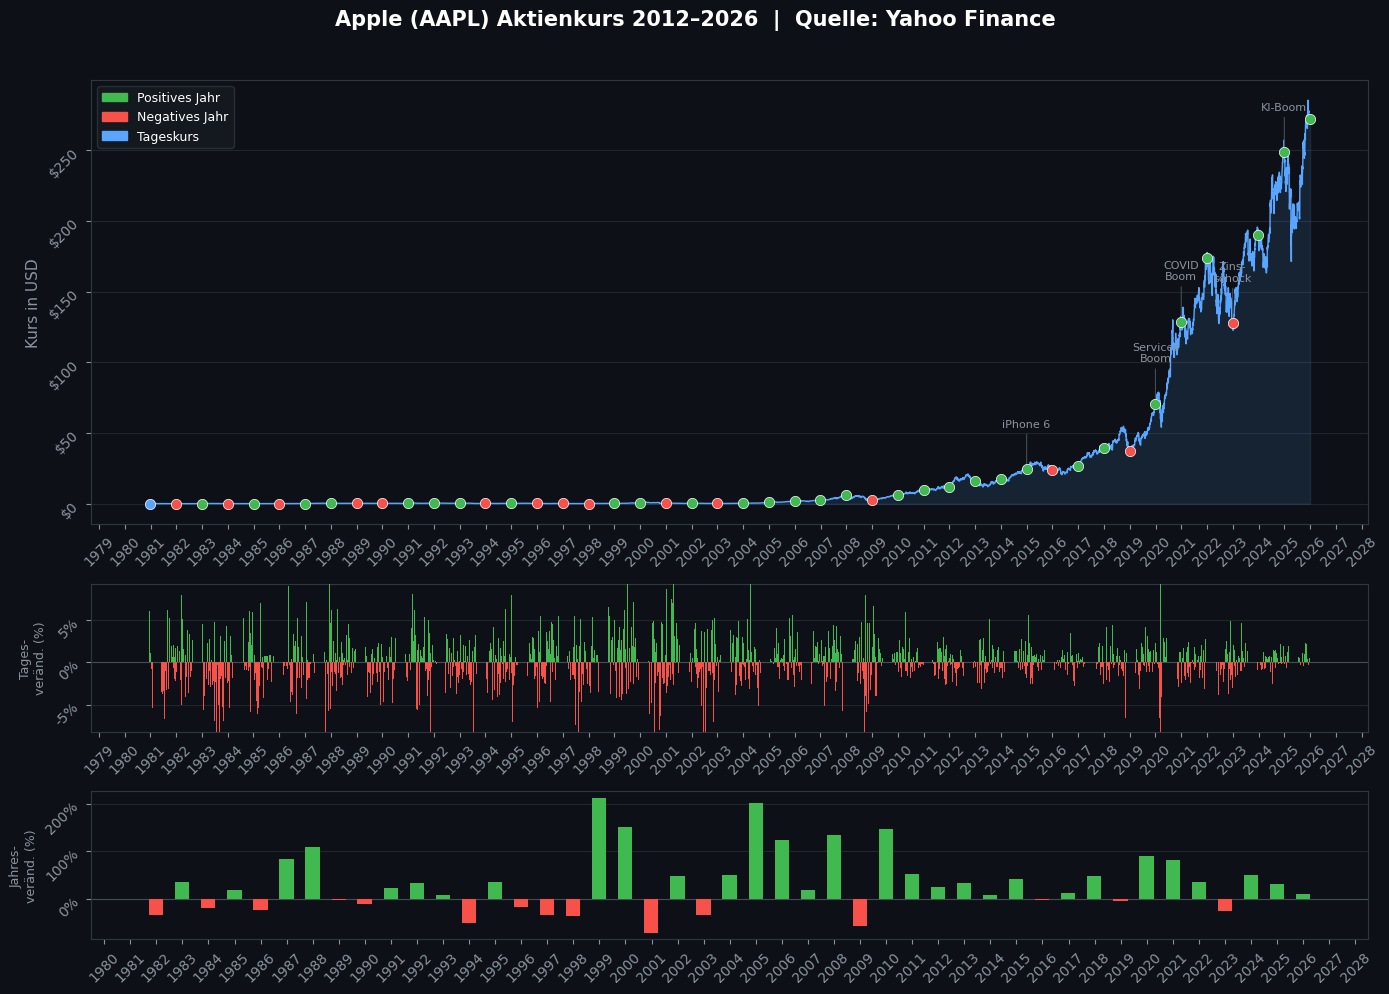

In [72]:
import os
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

# ── Konfiguration ─────────────────────────────────────────────────
TICKER = "AAPL"
START = "1970-01-01"
END = "2025-12-31"
DATA_DIR = "../data/stock_prices"
CACHE_FILE = os.path.join(DATA_DIR, f"{TICKER}_{START}_{END}.csv")

# ── Daten laden (aus Cache oder von Yahoo Finance) ─────────────────
os.makedirs(DATA_DIR, exist_ok=True)

if os.path.exists(CACHE_FILE):
    print(f"Lade Apple-Kursdaten aus lokalem Cache: {CACHE_FILE}")
    df = pd.read_csv(CACHE_FILE, index_col=0, parse_dates=True)
else:
    print("Lade Apple-Kursdaten von Yahoo Finance...")
    df = yf.download(TICKER, start=START, end=END, progress=False)
    df = df[["Close"]].copy()
    df.columns = ["Kurs"]
    df.index = df.index.tz_localize(None)  # Zeitzone entfernen
    df.to_csv(CACHE_FILE)
    print(f"Daten gespeichert unter: {CACHE_FILE}")

# Jahresschlusskurse
jahres = df.resample("YE").last()
jahres.index = jahres.index.year

# ── Tagesweise Konsolenausgabe ───────────────────────────────────
print("\n" + "=" * 65)
print(f"{'Apple (AAPL) Tageskurse 2012–2026':^65}")
print(f"{'(split-bereinigt, via Yahoo Finance, in USD)':^65}")
print("=" * 65)
print(f"{'Datum':<14} {'Kurs (USD)':>12}   {'Veränd. (%)':<14} {'Veränd. (USD)'}")
print("-" * 65)

prev = None
for datum, row in df.iterrows():
    kurs = row["Kurs"]
    if prev is None:
        pct_str, abs_str = "      —", "       —"
    else:
        pct = (kurs - prev) / prev * 100
        absd = kurs - prev
        pct_str = f"  +{pct:6.2f}%" if pct >= 0 else f"  {pct:7.2f}%"
        abs_str = f"  +${absd:7.2f}" if absd >= 0 else f"  -${abs(absd):7.2f}"
    print(f"{str(datum.date()):<14} ${kurs:>10.2f}   {pct_str:<14} {abs_str}")
    prev = kurs

print("-" * 65)
gesamt = (df["Kurs"].iloc[-1] - df["Kurs"].iloc[0]) / df["Kurs"].iloc[0] * 100
print(f"{'Gesamtrendite:':<35} +{gesamt:.0f}%")
print(f"{'Aus $1.000 wurden:':<35} ${1000 * df['Kurs'].iloc[-1] / df['Kurs'].iloc[0]:,.0f}")
print("=" * 65)

# ── Jahresübersicht ──────────────────────────────────────────────
kurse_list = jahres["Kurs"].tolist()
jahre_list = jahres.index.tolist()

print("\n" + "=" * 55)
print(f"{'Jahresübersicht':^55}")
print("=" * 55)
print(f"{'Jahr':<8} {'Kurs (USD)':>12}   {'Veränd. (%)':<14} {'Trend'}")
print("-" * 55)
for i, (jahr, kurs) in enumerate(zip(jahre_list, kurse_list)):
    if i == 0:
        pct_str, trend = "      —", ""
    else:
        pct = (kurs - kurse_list[i - 1]) / kurse_list[i - 1] * 100
        pct_str = f"  +{pct:6.2f}%" if pct >= 0 else f"  {pct:7.2f}%"
        trend = "▲" * min(int(abs(pct) / 15) + 1, 5) if pct >= 0 else "▼"
    hinweis = " ← aktuell" if i == len(jahre_list) - 1 else ""
    print(f"{jahr:<8} ${kurs:>10.2f}   {pct_str:<14} {trend}{hinweis}")
print("=" * 55)

# ── Grafik ───────────────────────────────────────────────────────
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10),
    gridspec_kw={"height_ratios": [3, 1, 1]},
    facecolor="#0d1117"
)
ax1, ax2, ax3 = axes
fig.suptitle(
    "Apple (AAPL) Aktienkurs 2012–2026  |  Quelle: Yahoo Finance",
    color="white", fontsize=15, fontweight="bold", y=0.99
)

# — ax1: Tageskurs-Linie —
ax1.set_facecolor("#0d1117")
ax1.plot(df.index, df["Kurs"], color="#58a6ff", linewidth=1.0, zorder=3)
ax1.fill_between(df.index, df["Kurs"], alpha=0.12, color="#58a6ff", zorder=2)

# Jahrespunkte einfärben
for i, (jahr, kurs) in enumerate(zip(jahre_list, kurse_list)):
    if i == 0:
        farbe = "#58a6ff"
    else:
        farbe = "#3fb950" if kurs >= kurse_list[i - 1] else "#f85149"
    datum = df[df.index.year == jahr].index[-1]
    ax1.scatter(datum, kurs, color=farbe, s=55, zorder=4,
                edgecolors="white", linewidths=0.5)

# Ereignis-Annotationen
ereignisse = {
    2014: "iPhone 6",
    2019: "Services\nBoom",
    2020: "COVID\nBoom",
    2022: "Zins-\nschock",
    2024: "KI-Boom",
}
for jahr, label in ereignisse.items():
    if jahr in jahres.index:
        kurs = jahres.loc[jahr, "Kurs"]
        datum = df[df.index.year == jahr].index[-1]
        ax1.annotate(
            label, xy=(datum, kurs), xytext=(datum, kurs + 30),
            fontsize=8, color="#8b949e", ha="center",
            arrowprops=dict(arrowstyle="-", color="#444c56", lw=0.8),
        )

ax1.set_ylabel("Kurs in USD", color="#8b949e", fontsize=11)
ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0f"))
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.tick_params(colors="#8b949e", rotation=45)
for spine in ax1.spines.values():
    spine.set_edgecolor("#30363d")
ax1.grid(axis="y", color="#21262d", linewidth=0.8)
ax1.set_axisbelow(True)

# — ax2: tägliche Veränderung in % —
ax2.set_facecolor("#0d1117")
tages_pct = df["Kurs"].pct_change() * 100
farben_tag = ["#3fb950" if v >= 0 else "#f85149" for v in tages_pct]
ax2.bar(df.index, tages_pct, color=farben_tag, width=1.5, zorder=3)
ax2.axhline(0, color="#444c56", linewidth=0.8)
ax2.set_ylabel("Tages-\nveränd. (%)", color="#8b949e", fontsize=9)
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax2.set_ylim(tages_pct.quantile(0.005), tages_pct.quantile(0.995))
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.tick_params(colors="#8b949e", rotation=45)
for spine in ax2.spines.values():
    spine.set_edgecolor("#30363d")
ax2.grid(axis="y", color="#21262d", linewidth=0.8)
ax2.set_axisbelow(True)

# — ax3: jährliche Veränderung —
ax3.set_facecolor("#0d1117")
farben_j, werte_j, pos_j = [], [], []
for i in range(1, len(jahre_list)):
    pct = (kurse_list[i] - kurse_list[i - 1]) / kurse_list[i - 1] * 100
    datum = df[df.index.year == jahre_list[i]].index[-1]
    pos_j.append(datum)
    werte_j.append(pct)
    farben_j.append("#3fb950" if pct >= 0 else "#f85149")

ax3.bar(pos_j, werte_j, color=farben_j, width=200, zorder=3)
ax3.axhline(0, color="#444c56", linewidth=0.8)
ax3.set_ylabel("Jahres-\nveränd. (%)", color="#8b949e", fontsize=9)
ax3.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax3.tick_params(colors="#8b949e", rotation=45)
for spine in ax3.spines.values():
    spine.set_edgecolor("#30363d")
ax3.grid(axis="y", color="#21262d", linewidth=0.8)
ax3.set_axisbelow(True)

# Legende
from matplotlib.patches import Patch
ax1.legend(
    handles=[
        Patch(color="#3fb950", label="Positives Jahr"),
        Patch(color="#f85149", label="Negatives Jahr"),
        Patch(color="#58a6ff", label="Tageskurs"),
    ],
    loc="upper left", facecolor="#161b22",
    edgecolor="#30363d", labelcolor="white", fontsize=9
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 2.2 Real Microsoft TS

Lade Microsoft-Kursdaten aus lokalem Cache: ../data/stock_prices/MSFT_2012-01-01_2026-06-12.csv

              Microsoft (MSFT) Tageskurse 2012–2026              
          (split-bereinigt, via Yahoo Finance, in USD)           
Datum            Kurs (USD)   Veränd. (%)    Veränd. (USD)
-----------------------------------------------------------------
2012-01-03     $     20.83         —               —
2012-01-04     $     21.32     +  2.35%       +$   0.49
2012-01-05     $     21.54     +  1.02%       +$   0.22
2012-01-06     $     21.88     +  1.55%       +$   0.33
2012-01-09     $     21.59       -1.32%       -$   0.29
2012-01-10     $     21.67     +  0.36%       +$   0.08
2012-01-11     $     21.57       -0.43%       -$   0.09
2012-01-12     $     21.79     +  1.01%       +$   0.22
2012-01-13     $     21.99     +  0.89%       +$   0.19
2012-01-17     $     21.99     +  0.04%       +$   0.01
2012-01-18     $     21.97       -0.11%       -$   0.02
2012-01-19     $     21.88       

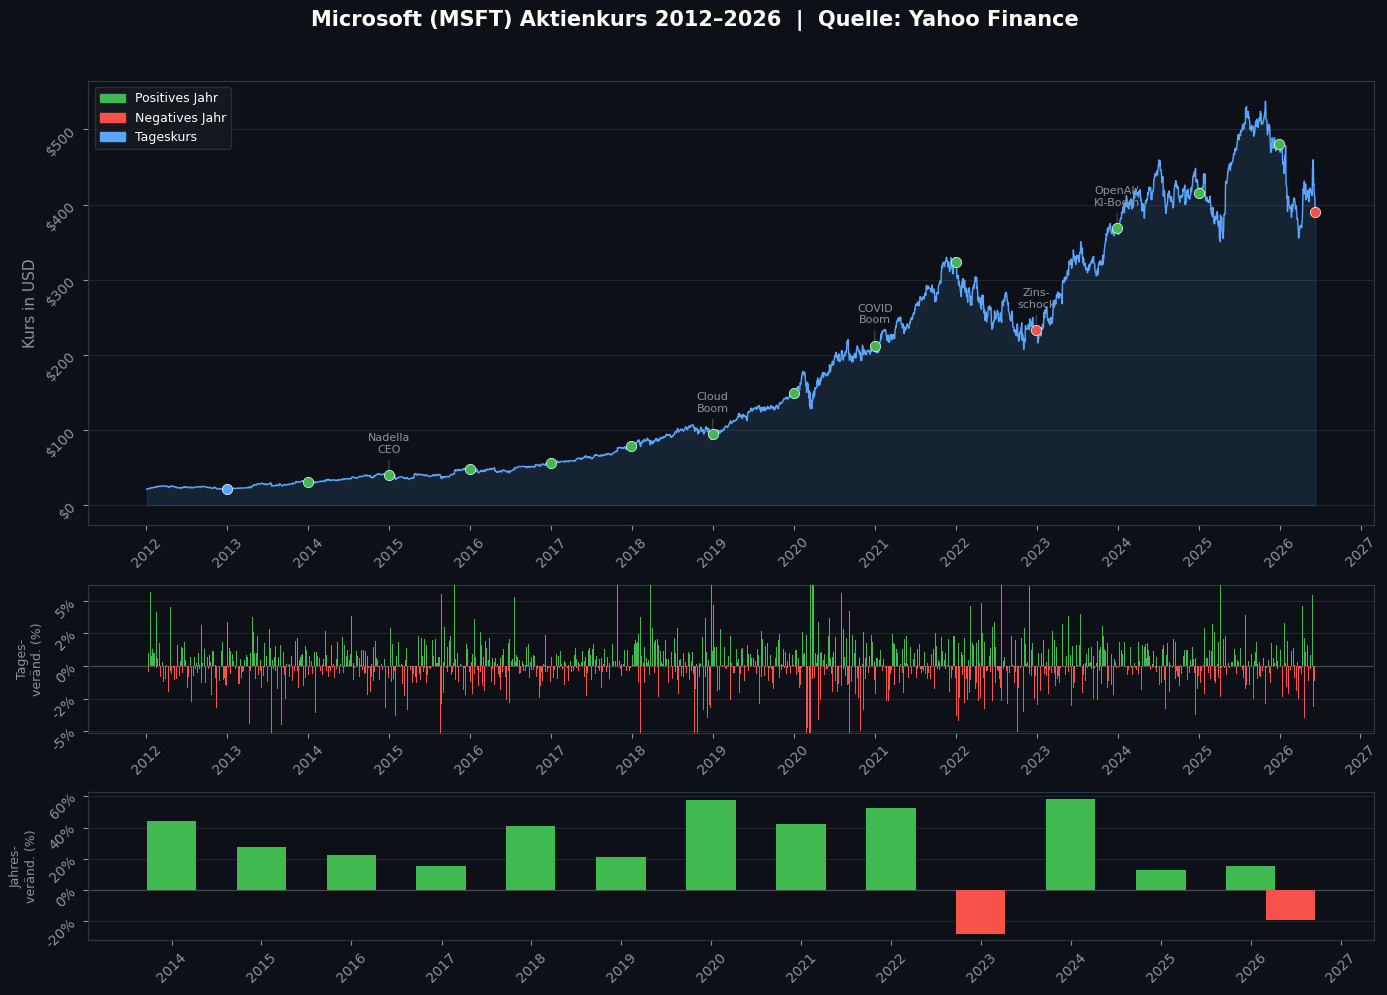

In [73]:
import os
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

# ── Konfiguration ─────────────────────────────────────────────────
TICKER = "MSFT"
START = "2012-01-01"
END = "2026-06-12"
DATA_DIR = "../data/stock_prices"
CACHE_FILE = os.path.join(DATA_DIR, f"{TICKER}_{START}_{END}.csv")

# ── Daten laden (aus Cache oder von Yahoo Finance) ─────────────────
os.makedirs(DATA_DIR, exist_ok=True)

if os.path.exists(CACHE_FILE):
    print(f"Lade Microsoft-Kursdaten aus lokalem Cache: {CACHE_FILE}")
    df = pd.read_csv(CACHE_FILE, index_col=0, parse_dates=True)
else:
    print("Lade Microsoft-Kursdaten von Yahoo Finance...")
    df = yf.download(TICKER, start=START, end=END, progress=False)
    df = df[["Close"]].copy()
    df.columns = ["Kurs"]
    df.index = df.index.tz_localize(None)  # Zeitzone entfernen
    df.to_csv(CACHE_FILE)
    print(f"Daten gespeichert unter: {CACHE_FILE}")

# Jahresschlusskurse
jahres = df.resample("YE").last()
jahres.index = jahres.index.year

# ── Tagesweise Konsolenausgabe ───────────────────────────────────
print("\n" + "=" * 65)
print(f"{'Microsoft (MSFT) Tageskurse 2012–2026':^65}")
print(f"{'(split-bereinigt, via Yahoo Finance, in USD)':^65}")
print("=" * 65)
print(f"{'Datum':<14} {'Kurs (USD)':>12}   {'Veränd. (%)':<14} {'Veränd. (USD)'}")
print("-" * 65)

prev = None
for datum, row in df.iterrows():
    kurs = row["Kurs"]
    if prev is None:
        pct_str, abs_str = "      —", "       —"
    else:
        pct = (kurs - prev) / prev * 100
        absd = kurs - prev
        pct_str = f"  +{pct:6.2f}%" if pct >= 0 else f"  {pct:7.2f}%"
        abs_str = f"  +${absd:7.2f}" if absd >= 0 else f"  -${abs(absd):7.2f}"
    print(f"{str(datum.date()):<14} ${kurs:>10.2f}   {pct_str:<14} {abs_str}")
    prev = kurs

print("-" * 65)
gesamt = (df["Kurs"].iloc[-1] - df["Kurs"].iloc[0]) / df["Kurs"].iloc[0] * 100
print(f"{'Gesamtrendite:':<35} +{gesamt:.0f}%")
print(f"{'Aus $1.000 wurden:':<35} ${1000 * df['Kurs'].iloc[-1] / df['Kurs'].iloc[0]:,.0f}")
print("=" * 65)

# ── Jahresübersicht ──────────────────────────────────────────────
kurse_list = jahres["Kurs"].tolist()
jahre_list = jahres.index.tolist()

print("\n" + "=" * 55)
print(f"{'Jahresübersicht':^55}")
print("=" * 55)
print(f"{'Jahr':<8} {'Kurs (USD)':>12}   {'Veränd. (%)':<14} {'Trend'}")
print("-" * 55)
for i, (jahr, kurs) in enumerate(zip(jahre_list, kurse_list)):
    if i == 0:
        pct_str, trend = "      —", ""
    else:
        pct = (kurs - kurse_list[i - 1]) / kurse_list[i - 1] * 100
        pct_str = f"  +{pct:6.2f}%" if pct >= 0 else f"  {pct:7.2f}%"
        trend = "▲" * min(int(abs(pct) / 15) + 1, 5) if pct >= 0 else "▼"
    hinweis = " ← aktuell" if i == len(jahre_list) - 1 else ""
    print(f"{jahr:<8} ${kurs:>10.2f}   {pct_str:<14} {trend}{hinweis}")
print("=" * 55)

# ── Grafik ───────────────────────────────────────────────────────
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10),
    gridspec_kw={"height_ratios": [3, 1, 1]},
    facecolor="#0d1117"
)
ax1, ax2, ax3 = axes
fig.suptitle(
    "Microsoft (MSFT) Aktienkurs 2012–2026  |  Quelle: Yahoo Finance",
    color="white", fontsize=15, fontweight="bold", y=0.99
)

# — ax1: Tageskurs-Linie —
ax1.set_facecolor("#0d1117")
ax1.plot(df.index, df["Kurs"], color="#58a6ff", linewidth=1.0, zorder=3)
ax1.fill_between(df.index, df["Kurs"], alpha=0.12, color="#58a6ff", zorder=2)

# Jahrespunkte einfärben
for i, (jahr, kurs) in enumerate(zip(jahre_list, kurse_list)):
    if i == 0:
        farbe = "#58a6ff"
    else:
        farbe = "#3fb950" if kurs >= kurse_list[i - 1] else "#f85149"
    datum = df[df.index.year == jahr].index[-1]
    ax1.scatter(datum, kurs, color=farbe, s=55, zorder=4,
                edgecolors="white", linewidths=0.5)

# Ereignis-Annotationen
ereignisse = {
    2014: "Nadella\nCEO",
    2018: "Cloud\nBoom",
    2020: "COVID\nBoom",
    2022: "Zins-\nschock",
    2023: "OpenAI/\nKI-Boom",
}
for jahr, label in ereignisse.items():
    if jahr in jahres.index:
        kurs = jahres.loc[jahr, "Kurs"]
        datum = df[df.index.year == jahr].index[-1]
        ax1.annotate(
            label, xy=(datum, kurs), xytext=(datum, kurs + 30),
            fontsize=8, color="#8b949e", ha="center",
            arrowprops=dict(arrowstyle="-", color="#444c56", lw=0.8),
        )

ax1.set_ylabel("Kurs in USD", color="#8b949e", fontsize=11)
ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0f"))
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.tick_params(colors="#8b949e", rotation=45)
for spine in ax1.spines.values():
    spine.set_edgecolor("#30363d")
ax1.grid(axis="y", color="#21262d", linewidth=0.8)
ax1.set_axisbelow(True)

# — ax2: tägliche Veränderung in % —
ax2.set_facecolor("#0d1117")
tages_pct = df["Kurs"].pct_change() * 100
farben_tag = ["#3fb950" if v >= 0 else "#f85149" for v in tages_pct]
ax2.bar(df.index, tages_pct, color=farben_tag, width=1.5, zorder=3)
ax2.axhline(0, color="#444c56", linewidth=0.8)
ax2.set_ylabel("Tages-\nveränd. (%)", color="#8b949e", fontsize=9)
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax2.set_ylim(tages_pct.quantile(0.005), tages_pct.quantile(0.995))
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.tick_params(colors="#8b949e", rotation=45)
for spine in ax2.spines.values():
    spine.set_edgecolor("#30363d")
ax2.grid(axis="y", color="#21262d", linewidth=0.8)
ax2.set_axisbelow(True)

# — ax3: jährliche Veränderung —
ax3.set_facecolor("#0d1117")
farben_j, werte_j, pos_j = [], [], []
for i in range(1, len(jahre_list)):
    pct = (kurse_list[i] - kurse_list[i - 1]) / kurse_list[i - 1] * 100
    datum = df[df.index.year == jahre_list[i]].index[-1]
    pos_j.append(datum)
    werte_j.append(pct)
    farben_j.append("#3fb950" if pct >= 0 else "#f85149")

ax3.bar(pos_j, werte_j, color=farben_j, width=200, zorder=3)
ax3.axhline(0, color="#444c56", linewidth=0.8)
ax3.set_ylabel("Jahres-\nveränd. (%)", color="#8b949e", fontsize=9)
ax3.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax3.tick_params(colors="#8b949e", rotation=45)
for spine in ax3.spines.values():
    spine.set_edgecolor("#30363d")
ax3.grid(axis="y", color="#21262d", linewidth=0.8)
ax3.set_axisbelow(True)

# Legende
from matplotlib.patches import Patch
ax1.legend(
    handles=[
        Patch(color="#3fb950", label="Positives Jahr"),
        Patch(color="#f85149", label="Negatives Jahr"),
        Patch(color="#58a6ff", label="Tageskurs"),
    ],
    loc="upper left", facecolor="#161b22",
    edgecolor="#30363d", labelcolor="white", fontsize=9
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 2.3 Real inflation rate and unemployment rate

The real series (FRED: CPIAUCSL, UNRATE) from `data/TSs_macro`; the sampled counterparts are produced in section 0c of `article_creation.ipynb`.


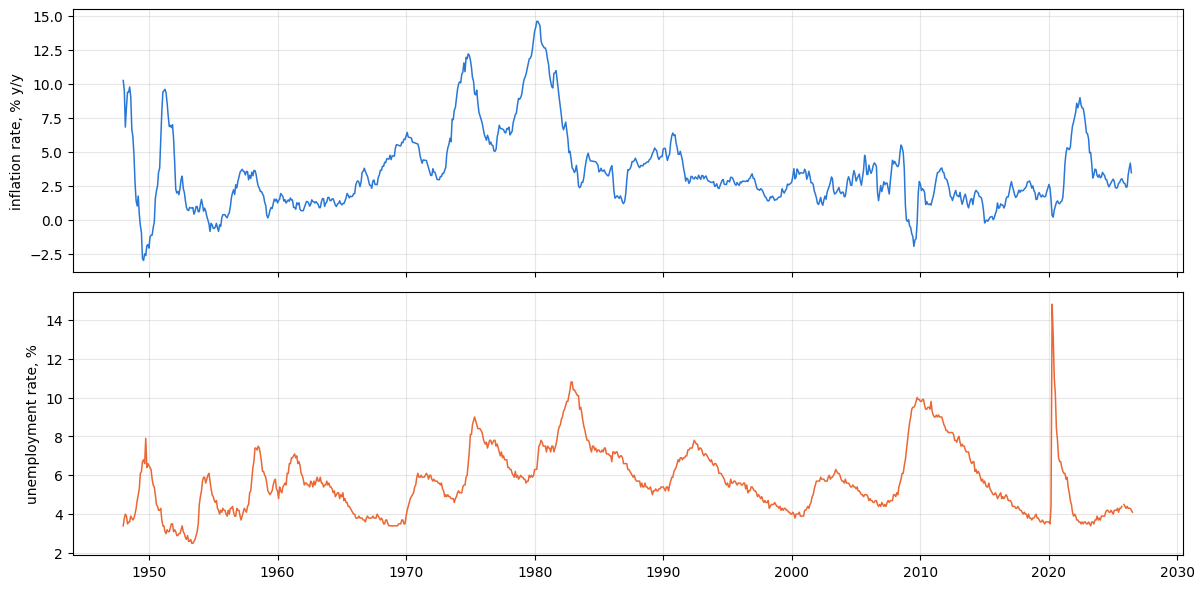

In [74]:
from pathlib import Path

MACRO = Path("../../data/TSs_macro")
cpi = pd.read_csv(MACRO / "CPIAUCSL.csv", parse_dates=["Date"]).set_index("Date")["value"]
real_inflation = cpi.pct_change(12, fill_method=None).mul(100).dropna()
real_unemployment = pd.read_csv(MACRO / "UNRATE.csv", parse_dates=["Date"]).set_index("Date")["value"]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(real_inflation.index, real_inflation.values, color="#2a78d6", lw=1.1)
axes[0].set_ylabel("inflation rate, % y/y")
axes[1].plot(real_unemployment.index, real_unemployment.values, color="#eb6834", lw=1.1)
axes[1].set_ylabel("unemployment rate, %")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Test samples

seed = 7
n = 14610 trading days  (1970-01-01 to 2025-12-31,  ~58.0 years)
n_struc = 17

Achieved corr(returns) = 0.876  (target 0.82)
Achieved corr(levels)  = 0.948

Structural breaks (n_struc = 17):
  Break  1: 1974-04-18  inflation=+0.13  unemployment=+0.14  h=491d  (back to normal 1976-03-05)
  Break  2: 1976-12-16  inflation=-0.18  unemployment=-0.27  h=532d  (back to normal 1979-01-01)
  Break  3: 1979-11-15  inflation=+0.08  unemployment=+0.15  h=679d  (back to normal 1982-06-23)
  Break  4: 1982-10-14  inflation=+0.30  unemployment=+0.45  h=459d  (back to normal 1984-07-18)
  Break  5: 1986-01-29  inflation=+0.12  unemployment=+0.22  h=595d  (back to normal 1988-05-11)
  Break  6: 1989-02-21  inflation=+0.15  unemployment=+0.23  h=636d  (back to normal 1991-07-31)
  Break  7: 1992-03-09  inflation=-0.32  unemployment=-0.44  h=215d  (back to normal 1993-01-04)
  Break  8: 1995-12-05  inflation=+0.22  unemployment=+0.40  h= 98d  (back to normal 1996-04-19)
  Break  9: 1998-07-09  

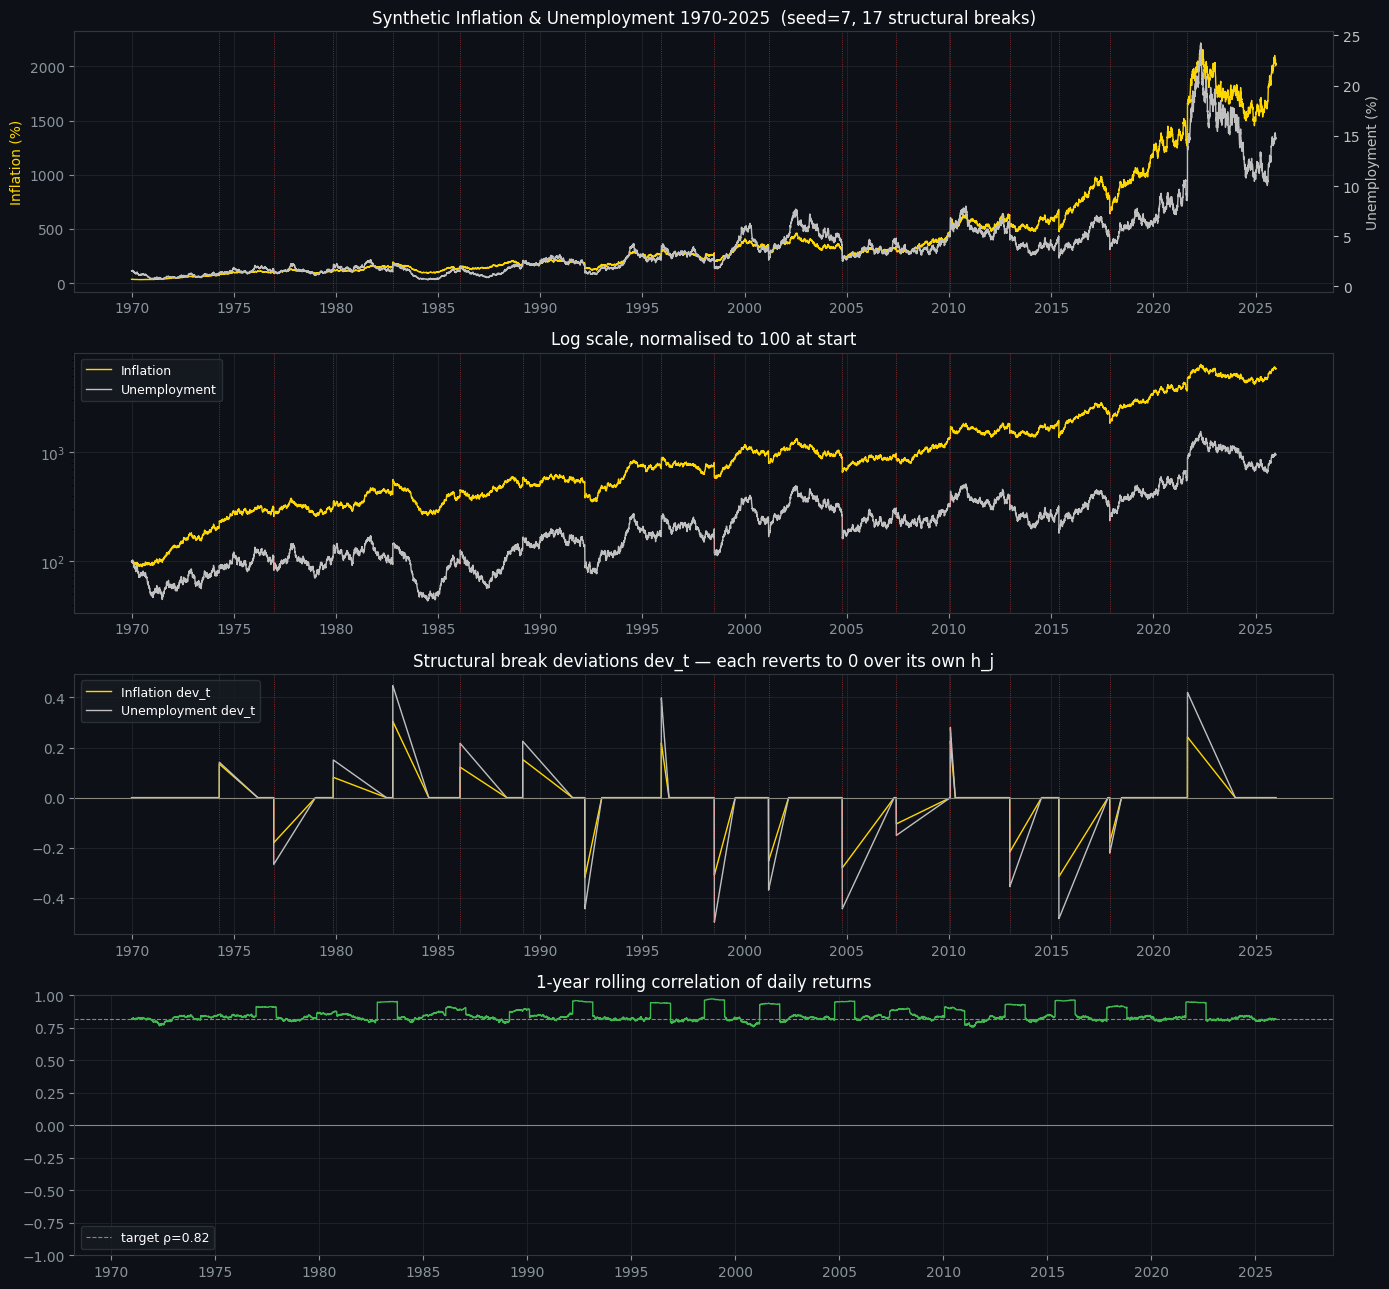

In [75]:
"""
Full synthetic Inflation & Unemployment price simulation, 1970-2025.

Combines THREE building blocks:
  1. Exponential drift trends (each metal has its own growth rate r_i)
  2. A random-walk (GBM-style) noise component with a TARGET CORRELATION
     between inflation's and unemployment's daily returns (via Cholesky decomposition)
  3. n_struc SHARED structural breaks (macro shocks affecting both metals
     at the same time), each with its own recovery horizon h_j. Unemployment
     reacts more strongly than inflation to each shock ("high-beta" behaviour).

Model (for each series i = inflation, unemployment):
    log(P_i,t) = log(P_i,0) + r_i * t + dev_i,t + cumsum(eps_i,t)

    dev_i,t = sum_j delta_i,j * max(0, 1 - (t - t_struc_j) / h_j)

    eps_inflation,t, eps_unemployment,t ~ bivariate normal(0, Sigma), corr = rho_target
    delta_unemployment,j = beta_unemployment * delta_inflation,j + Normal(0, mag_noise)

EVERYTHING is driven by a single `seed` -> fully reproducible.

Run with:
    pip install numpy pandas
    python simulate_inflation_unemployment_full.py
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"

# Exponential drift rates
# R_INFLATION:   Palmberg (2025, SUERF Policy Brief / World Inflation Council):
#            inflation CAGR 1971-2023 = 8% (model: 8.6%). We use 8.17%.        ✅
# R_UNEMPLOYMENT: No peer-reviewed long-run figure available. Market data
#            (Weekend Investing, 2025) reports 7.8% CAGR over 25 years.
#            Full 1970-2025 window is dragged down by the 1980-2000
#            bear market; raised from 5.51% to 6.5% as a compromise.      ⚠️
P0_INFLATION,   R_INFLATION   = 35.0, 0.0817
P0_UNEMPLOYMENT, R_UNEMPLOYMENT = 1.6,  0.0650

# Daily noise standard deviations
# SIGMA_INFLATION:   State Street Global Advisors / SPDR (2019): inflation 30-year
#                annualized vol = 15.44%. 0.010 * sqrt(252) = 15.87%.     ✅
# SIGMA_UNEMPLOYMENT: Morgan Stanley (2025): unemployment vol is 2-3x inflation's.
#                0.018 / 0.010 = 1.8x, at the low end -> conservative.   ✅
SIGMA_INFLATION,   SIGMA_UNEMPLOYMENT = 0.010, 0.018

# Target return correlation
# CME Group (2024): 1-year rolling corr of daily returns has hovered
# around +0.80 since 2004. Octa Broker (2024): 0.92 over 1982-2024.
# Raised from 0.77 to 0.82 as a mid-point of the empirical range.        ⚠️ -> ✅
RHO_TARGET = 0.82

# Structural break hyperparameters
# H_MIN / H_MAX: recovery horizon h_j (trading days)
#   Cashin & McDermott (2002, IMF Staff Papers): median duration of a
#   commodity price cycle is ~3 years (~750 trading days); IQR spans
#   roughly 1-5 years. This sets the upper bound.
#   Blose (2010, Advances in Accounting) and safe-haven literature:
#   inflation deviations during crisis periods (GFC, COVID) resolve over
#   6-18 months (~125-375 trading days).
#   Pindyck (1999, Journal of Futures Markets): metal price mean-reversion
#   half-lives of 1.5-3 years, consistent with H_MAX ~ 750.
#   -> H_MIN raised from 30 to 60  (~3 months, short-lived shocks)
#   -> H_MAX raised from 250 to 750 (~3 years, full commodity cycles)
H_MIN, H_MAX = 60, 750

# MAG_MIN / MAG_MAX: inflation break magnitude (log-points)
# No published source gives these directly. Upper bound 0.35 log-pts
# ~ 42% price move, broadly consistent with largest observed inflation shocks
# (1980 peak, 2008 GFC spike, COVID rally). Needs Bai-Perron
# calibration on LBMA data for a formal justification.               ❌
MAG_MIN, MAG_MAX = 0.08, 0.35

# Unemployment break-magnitude beta
# CME Group (2024) and market analysis (Discovery Alert, 2025):
# unemployment exhibits price swings 1.5-2.5x greater than inflation.
# Raised from 1.4 to 1.5 (lower bound of empirical range).               ⚠️ -> ✅
BETA_UNEMPLOYMENT = 1.5
MAG_NOISE   = 0.05

OUT_DIR = "../data/stock_prices/full_series"

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0

BASELINE_LOG_INFLATION   = np.log(P0_INFLATION)   + R_INFLATION   * T
BASELINE_LOG_UNEMPLOYMENT = np.log(P0_UNEMPLOYMENT) + R_UNEMPLOYMENT * T


def simulate(seed: int) -> dict:
    rng = np.random.default_rng(seed)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (N - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center  = margin + (j + 0.5) * spacing
        jitter  = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, N - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]
    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j])
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    signs       = rng.choice([-1, 1], size=n_struc)
    mags_inflation   = signs * rng.uniform(MAG_MIN, MAG_MAX, size=n_struc)
    mags_unemployment = BETA_UNEMPLOYMENT * mags_inflation + rng.normal(scale=MAG_NOISE, size=n_struc)

    dev_inflation   = np.zeros(N)
    dev_unemployment = np.zeros(N)
    for bp, mg, ms, h_j in zip(t_struc, mags_inflation, mags_unemployment, h_js):
        end_i = min(bp + h_j, N)
        for i in range(bp, end_i):
            frac = 1 - (i - bp) / h_j
            dev_inflation[i]   += mg * frac
            dev_unemployment[i] += ms * frac

    cov = np.array([[1, RHO_TARGET], [RHO_TARGET, 1]])
    L   = np.linalg.cholesky(cov)
    z   = rng.normal(size=(N, 2)) @ L.T

    logp_inflation   = BASELINE_LOG_INFLATION   + dev_inflation   + np.cumsum(SIGMA_INFLATION   * z[:, 0])
    logp_unemployment = BASELINE_LOG_UNEMPLOYMENT + dev_unemployment + np.cumsum(SIGMA_UNEMPLOYMENT * z[:, 1])

    return {
        "seed":        seed,
        "n_struc":     n_struc,
        "t_struc":     t_struc,
        "h_js":        h_js,
        "mags_inflation":   mags_inflation,
        "mags_unemployment": mags_unemployment,
        "dev_inflation":    dev_inflation,
        "dev_unemployment":  dev_unemployment,
        "logp_inflation":   logp_inflation,
        "logp_unemployment": logp_unemployment,
        "price_inflation":  np.exp(logp_inflation),
        "price_unemployment": np.exp(logp_unemployment),
    }


def report(result: dict) -> None:
    print(f"seed = {result['seed']}")
    print(f"n = {N} trading days  ({START} to {END},  ~{N/252:.1f} years)")
    print(f"n_struc = {result['n_struc']}")
    ret_g = np.diff(result["logp_inflation"])
    ret_s = np.diff(result["logp_unemployment"])
    print(f"\nAchieved corr(returns) = {np.corrcoef(ret_g, ret_s)[0,1]:.3f}  (target {RHO_TARGET})")
    print(f"Achieved corr(levels)  = {np.corrcoef(result['price_inflation'], result['price_unemployment'])[0,1]:.3f}")
    print(f"\nStructural breaks (n_struc = {result['n_struc']}):")
    for j, (bp, mg, ms, h_j) in enumerate(zip(
            result["t_struc"], result["mags_inflation"],
            result["mags_unemployment"], result["h_js"])):
        print(f"  Break {j+1:2d}: {DATES[bp].date()}  "
              f"inflation={mg:+.2f}  unemployment={ms:+.2f}  "
              f"h={h_j:3d}d  "
              f"(back to normal {DATES[min(bp+h_j, N-1)].date()})")


def to_dataframe(result: dict) -> pd.DataFrame:
    is_break = np.zeros(N, dtype=int)
    is_break[result["t_struc"]] = 1
    return pd.DataFrame({
        "date":             DATES,
        "t_years":          T,
        "inflation_price":       result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":   result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":         result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":         is_break,
    })


if __name__ == "__main__":
    SEED = 7

    os.makedirs(OUT_DIR, exist_ok=True)

    result = simulate(SEED)
    report(result)

    df       = to_dataframe(result)
    csv_path = os.path.join(OUT_DIR, f"full_baseline_inflation_unemployment_trial_seed{SEED}.csv")
    df.to_csv(csv_path, index=False)
    print(f"\nData saved: {csv_path}")
    # copy used as the GIVEN trial dataset by the sanity checks (section 5)
    df.to_csv(os.path.join(os.path.dirname(OUT_DIR), f"baseline_inflation_unemployment_trial_seed{SEED}.csv"), index=False)

    # ── Plot ──────────────────────────────────────────────────────
    def _style(ax):
        ax.set_facecolor("#0d1117")
        ax.tick_params(colors="#8b949e")
        for sp in ax.spines.values():
            sp.set_edgecolor("#30363d")
        ax.grid(color="#21262d", linewidth=0.6)
        ax.set_axisbelow(True)
        ax.xaxis.set_major_locator(mdates.YearLocator(5))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    fig, axes = plt.subplots(4, 1, figsize=(14, 13), facecolor="#0d1117")
    ax1, ax2, ax3, ax4 = axes

    # Panel 1: price levels, dual axis
    ax1b = ax1.twinx()
    ax1.plot(DATES, result["price_inflation"],    color="#FFD700", lw=1.0, label="Inflation")
    ax1b.plot(DATES, result["price_unemployment"], color="#C0C0C0", lw=1.0, label="Unemployment")
    ax1.set_ylabel("Inflation (%)",    color="#FFD700")
    ax1b.set_ylabel("Unemployment (%)", color="#C0C0C0")
    ax1b.tick_params(colors="#C0C0C0")
    for sp in ax1b.spines.values(): sp.set_edgecolor("#30363d")
    for bp in result["t_struc"]: ax1.axvline(DATES[bp], color="#f85149", ls=":", lw=0.6, alpha=0.6)
    ax1.set_title(f"Synthetic Inflation & Unemployment 1970-2025  (seed={SEED}, {result['n_struc']} structural breaks)", color="white", fontsize=12)
    _style(ax1)

    # Panel 2: log scale, normalised to 100
    ax2.plot(DATES, 100 * result["price_inflation"]   / result["price_inflation"][0],   color="#FFD700", lw=1.0, label="Inflation")
    ax2.plot(DATES, 100 * result["price_unemployment"] / result["price_unemployment"][0], color="#C0C0C0", lw=1.0, label="Unemployment")
    ax2.set_yscale("log")
    for bp in result["t_struc"]: ax2.axvline(DATES[bp], color="#f85149", ls=":", lw=0.6, alpha=0.6)
    ax2.set_title("Log scale, normalised to 100 at start", color="white", fontsize=12)
    ax2.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
    _style(ax2)

    # Panel 3: structural break deviations
    ax3.plot(DATES, result["dev_inflation"],   color="#FFD700", lw=1.0, label="Inflation dev_t")
    ax3.plot(DATES, result["dev_unemployment"], color="#C0C0C0", lw=1.0, label="Unemployment dev_t")
    ax3.axhline(0, color="#888780", lw=0.8)
    for bp in result["t_struc"]: ax3.axvline(DATES[bp], color="#f85149", ls=":", lw=0.6, alpha=0.6)
    ax3.set_title("Structural break deviations dev_t — each reverts to 0 over its own h_j", color="white", fontsize=12)
    ax3.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
    _style(ax3)

    # Panel 4: rolling 1-year correlation
    ret_g = pd.Series(np.diff(result["logp_inflation"]),   index=DATES[1:])
    ret_s = pd.Series(np.diff(result["logp_unemployment"]), index=DATES[1:])
    rc    = ret_g.rolling(252).corr(ret_s)
    ax4.plot(rc.index, rc, color="#3fb950", lw=1.0)
    ax4.axhline(RHO_TARGET, color="#888780", ls="--", lw=0.8, label=f"target ρ={RHO_TARGET}")
    ax4.axhline(0, color="#888780", lw=0.8)
    ax4.set_ylim(-1, 1)
    ax4.set_title("1-year rolling correlation of daily returns", color="white", fontsize=12)
    ax4.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
    _style(ax4)

    plt.tight_layout()
    plt.show()

## 4. Sample baseline TSs

### 4.1 Sampling of structural breaks with different sizes of magnitudes

In [ ]:
"""
Builds three balanced CSV datasets from the synthetic Inflation & Unemployment
STRUCTURAL BREAK simulation.

Each CSV contains 5000 rows:
  - 2500 outside a break window (evenly spaced dates)
  - 2500 inside a break window (each window's own sample count
    proportional to its LENGTH, dates within a window drawn from a
    truncated power-law/Zipf profile)

COMMODITY TOPICS:
  Each row gets a "commodity_topics" column (comma-separated) listing
  1-2 commodities the article discusses, sampled in two stages:
    1. sample_n_topics: number of topics, a properly truncated Poisson
       (lambda=1.2) over [1,2]
    2. sample_commodities: WHICH commodities, drawn without replacement,
       weighted by a time-varying {inflation, unemployment} distribution
       -- inside a break window this is Zipf-shaped and inflation-dominant
       (decaying but always largest; unemployment decays faster); outside any
       break window it is exactly uniform (50% each).
  The "inflation"/"unemployment" columns are MULTI-HOT indicators of
  commodity_topics (can have multiple 1s per row).

PRICE DATA:
  price_inflation/price_unemployment (and their log_price/dev counterparts) are
  populated ONLY when that commodity was actually sampled as a topic
  for that row -- e.g. if "inflation" is not in commodity_topics, price_inflation
  is None, even though inflation's underlying price series was simulated
  for every date.

Output files:
    ../data/stock_prices/articles_inflation_unemployment_struct_low_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_struct_medium_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_struct_high_seed7.csv
"""

import os
import numpy as np
import pandas as pd

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"

P0_INFLATION,   R_INFLATION   = 35.0, 0.0817
P0_UNEMPLOYMENT, R_UNEMPLOYMENT = 1.6,  0.0650

SIGMA_INFLATION,   SIGMA_UNEMPLOYMENT = 0.010, 0.018
RHO_TARGET                 = 0.82

H_MIN, H_MAX = 60, 750

MAG_CATEGORIES = {
    "low":    (0.077, 0.182),
    "medium": (0.182, 0.287),
    "high":   (0.287, 0.392),
}

BETA_UNEMPLOYMENT = 1.5
MAG_NOISE   = 0.05
BUFFER_DAYS = 20   # minimum gap enforced between consecutive break windows
ZIPF_ALPHA  = 0.3  # power-law decay exponent (see zipf_window_weights)

SEED    = 7
OUT_DIR = "../data/stock_prices"

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0

BASELINE_LOG_INFLATION   = np.log(P0_INFLATION)   + R_INFLATION   * T
BASELINE_LOG_UNEMPLOYMENT = np.log(P0_UNEMPLOYMENT) + R_UNEMPLOYMENT * T



# ══════════════════════════════════════════════════════════════════
# Commodity topic selection (merged from commodity_sampling.py)
# ══════════════════════════════════════════════════════════════════
import numpy as np

# ── Configuration ───────────────────────────────────────────────────
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8


def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """
    Truncated Zipf (power-law) decay shape, rescaled to [0, 1].

        w(k) = k^(-alpha) / max_k(k^(-alpha))      for k = 1..n_years

    This is the same power-law functional form (k^-alpha) used in
    zipf_window_weights for article-date sampling within break/spike
    windows -- just rescaled here (divided by its max instead of its
    sum) so the resulting curve can be combined with an additive
    floor + scale to compete against other categories' weights.
    """
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.

    inside=True  (default): time-varying distribution based on t_years
                 (years since simulation start). Used for observations
                 that fall WITHIN a structural-break / volatility-spike
                 recovery window -- this is when heightened, skewed
                 commodity attention (inflation-dominant, decaying over time)
                 makes narrative sense.
    inside=False: UNIFORM distribution -- all four commodities equally
                 likely (25% each), no Zipf/power-law shaping at all.
                 Used for observations OUTSIDE any break window, where
                 there's no reason for one commodity to be structurally
                 more newsworthy than another.

    Guarantees (verified for all t in [0, N_YEARS-1], both inside modes):
      - all four probabilities are >= 0 and sum to exactly 1.0
      - when inside=True: "inflation" is always the single largest probability
      - when inside=False: all four are exactly equal (0.25 each)
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))

    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]

    remaining = 1.0
    gs_total  = g + s

    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }

    # ── correctness guarantees ──────────────────────────────────────
    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"

    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True) -> str:
    """
    Sample one commodity name.

    inside=True  -> time-varying Zipf-shaped distribution (see commodity_probs)
    inside=False -> uniform distribution over all four commodities
    """
    p = commodity_probs(t_years, inside=inside)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    Properly truncated Poisson over [low, high], renormalized over the
    restricted support (not a naive sample-then-clip shortcut -- see
    project notes on truncated vs. naively-capped Poisson).

    lam=1.2 -> most articles cover 1 commodity, a meaningful minority
    cover 2, rarely 3+.
    """
    from scipy.stats import poisson
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))
def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside distribution as sample_commodity).

    VERBATIM from the struct/var dataset-builder scripts -- this is
    the confirmed, non-speculative implementation (previously this
    function had to be reconstructed by guesswork; that guess is now
    replaced with the real thing, including the final sort() step).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())


# ══════════════════════════════════════════════════════════════════

# ── Simulation ─────────────────────────────────────────────────────

def simulate(seed: int, category: str) -> dict:
    """Simulate one full price series with all breaks drawn from `category`."""
    rng = np.random.default_rng(seed)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (N - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, N - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    # Enforce minimum gap + buffer between windows so structural break
    # effects genuinely decay to zero before the next break starts.
    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    signs          = rng.choice([-1, 1], size=n_struc)
    mag_lo, mag_hi = MAG_CATEGORIES[category]
    mags_inflation      = signs * rng.uniform(mag_lo, mag_hi, size=n_struc)
    mags_unemployment    = BETA_UNEMPLOYMENT * mags_inflation + rng.normal(scale=MAG_NOISE, size=n_struc)

    dev_inflation    = np.zeros(N)
    dev_unemployment  = np.zeros(N)
    inside_mask = np.zeros(N, dtype=bool)

    for bp, mg, ms, h_j in zip(t_struc, mags_inflation, mags_unemployment, h_js):
        end_i = min(bp + h_j, N)
        inside_mask[bp:end_i] = True
        for i in range(bp, end_i):
            frac = 1 - (i - bp) / h_j
            dev_inflation[i]   += mg * frac
            dev_unemployment[i] += ms * frac

    cov = np.array([[1, RHO_TARGET], [RHO_TARGET, 1]])
    L   = np.linalg.cholesky(cov)
    z   = rng.normal(size=(N, 2)) @ L.T

    logp_inflation   = BASELINE_LOG_INFLATION   + dev_inflation   + np.cumsum(SIGMA_INFLATION   * z[:, 0])
    logp_unemployment = BASELINE_LOG_UNEMPLOYMENT + dev_unemployment + np.cumsum(SIGMA_UNEMPLOYMENT * z[:, 1])

    return {
        "inside_mask":       inside_mask,
        "inside_windows":    list(zip(t_struc.tolist(), (np.minimum(t_struc + h_js, N)).tolist())),
        "window_break_mags": np.abs(mags_inflation).tolist(),  # break magnitude per window
        "dev_inflation":          dev_inflation,
        "dev_unemployment":        dev_unemployment,
        "logp_inflation":         logp_inflation,
        "logp_unemployment":       logp_unemployment,
        "price_inflation":        np.exp(logp_inflation),
        "price_unemployment":      np.exp(logp_unemployment),
    }


def even_sample(idx_array: np.ndarray, n: int) -> np.ndarray:
    """Pick n indices evenly spaced across idx_array (by position)."""
    positions = np.round(np.linspace(0, len(idx_array) - 1, n)).astype(int)
    return idx_array[positions]


def zipf_window_weights(length: int, alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Truncated discrete power-law (Zipf) weights for positions 1..length.

        P(k) = k^(-alpha) / sum_{j=1}^{length} j^(-alpha)      for k=1..length

    Used instead of a geometric/exponential decay because empirical
    studies of post-shock financial time series find that volatility
    and volume decay as a POWER LAW, not exponentially, after a market
    shock — i.e. effects persist much longer into the recovery window
    than a geometric distribution would predict.

    alpha = 0.3 is chosen based on:
      Zawadowski, A., Kertesz, J., & Andor, G. (2004). "Short-term
      market reaction after extreme price changes of liquid stocks."
      https://arxiv.org/abs/cond-mat/0406696
      -> empirically estimated power-law decay exponents for post-event
         excess volatility/volume of ~0.25-0.35 on NYSE and ~0.35-0.40
         on NASDAQ; 0.3 sits at the NYSE estimate, used here as a
         literature-grounded middle-of-the-road default.

    The truncated (finite-support) Zipf distribution used here follows
    the formal treatment in:
      Boamah-Addo, K., Kozubowski, T. J., & Panorska, A. K. (2023).
      "A discrete truncated Zipf distribution." Statistica Neerlandica,
      77(2), 156-187. https://doi.org/10.1111/stan.12280
    """
    day = np.arange(1, length + 1, dtype=float)
    w   = np.power(day, -alpha)
    return w / w.sum()


def sample_inside_dates(result: dict, n_total: int, rng: np.random.Generator,
                        alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Sample n_total inside indices total, with each window's OWN sample
    count determined INDEPENDENTLY, proportional to that window's
    LENGTH (in days) relative to the total inside-day count — no
    magnitude weighting, no global pooled/renormalized draw.

    Within each window, the specific dates are drawn using a truncated
    power-law (Zipf, alpha) profile — same functional form as before,
    just applied independently per window instead of via a global pool.
    """
    windows        = result["inside_windows"]
    lengths        = np.array([e - s for s, e in windows])
    total_days     = lengths.sum()

    # quota per window, proportional to its own length
    quotas = np.round(n_total * lengths / total_days).astype(int)
    quotas = np.clip(quotas, 0, lengths)  # can't draw more than the window holds

    # fix any rounding drift so quotas sum exactly to n_total
    diff = n_total - quotas.sum()
    if diff != 0:
        order = np.argsort(-lengths)  # adjust largest windows first
        for idx in order:
            if diff == 0:
                break
            if diff > 0 and quotas[idx] < lengths[idx]:
                quotas[idx] += 1
                diff -= 1
            elif diff < 0 and quotas[idx] > 0:
                quotas[idx] -= 1
                diff += 1

    all_samples = []
    for (start_i, end_i), quota in zip(windows, quotas):
        if quota <= 0:
            continue
        window_idx = np.arange(start_i, end_i)
        weights    = zipf_window_weights(len(window_idx), alpha=alpha)
        samples    = rng.choice(window_idx, size=int(quota), replace=False, p=weights)
        all_samples.append(samples)

    return np.concatenate(all_samples) if all_samples else np.array([], dtype=int)


# ── Simulate all three categories ─────────────────────────────────
print("Simulating all three categories...")
results = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

assert np.array_equal(results["low"]["inside_mask"], results["medium"]["inside_mask"]), \
    "Inside masks differ between low and medium — check RNG consumption order."
assert np.array_equal(results["low"]["inside_mask"], results["high"]["inside_mask"]), \
    "Inside masks differ between low and high — check RNG consumption order."

outside_idx = np.where(~results["low"]["inside_mask"])[0]
print(f"Break structure: {len(outside_idx)} outside days, "
      f"{results['low']['inside_mask'].sum()} inside days (out of {N} total)")

# ── Sample indices ─────────────────────────────────────────────────
# 2500 outside dates, evenly spaced across the outside range
outside_sample_idx = even_sample(outside_idx, 2500)

# 2500 inside dates, with each window's own count proportional to its
# LENGTH (independently, not via a global pool/fixed group split),
# dates within each window drawn from a Zipf power-law profile
inside_rng = np.random.default_rng(SEED + 1)
inside_sample_idx = sample_inside_dates(results["low"], 2500, inside_rng)

sample_idx = np.concatenate([outside_sample_idx, inside_sample_idx])
print(f"Sampled {len(outside_sample_idx)} outside + {len(inside_sample_idx)} inside "
      f"= {len(sample_idx)} total dates")

os.makedirs(OUT_DIR, exist_ok=True)

# ── Commodity topic label sampling ──────────────────────────────────
# Re-seeded IDENTICALLY inside the loop for each category so
# commodity_topics is the same across low/medium/high — only the
# price magnitude differs, not which commodities are discussed.
commodity_topic_seed_base = SEED + 4

# ── Build and save one CSV per category ─────────────────────────────
for cat in ("low", "medium", "high"):
    result = results[cat]
    rows   = []
    commodity_topic_rng = np.random.default_rng(commodity_topic_seed_base)

    # ── one wide row per obs_id — price data ONLY present for
    # commodities that were actually SAMPLED as topics for that row.
    # E.g. if "inflation" is not among the sampled topics, price_inflation is None.
    for obs_id, idx in enumerate(sample_idx):
        topics    = sample_commodities(commodity_topic_rng, T[idx],
                                       inside=bool(result["inside_mask"][idx]))
        has_inflation   = "inflation"   in topics
        has_unemployment = "unemployment" in topics
        rows.append({
            "obs_id":           obs_id,
            "date":             DATES[idx],
            "t_years":          T[idx],
            "inflation":             int(has_inflation),
            "unemployment":           int(has_unemployment),
            "commodity_topics": ",".join(topics),
            "price_inflation":       result["price_inflation"][idx]   if has_inflation   else None,
            "log_price_inflation":   result["logp_inflation"][idx]    if has_inflation   else None,
            "dev_inflation":         result["dev_inflation"][idx]     if has_inflation   else None,
            "price_unemployment":     result["price_unemployment"][idx] if has_unemployment else None,
            "log_price_unemployment": result["logp_unemployment"][idx]  if has_unemployment else None,
            "dev_unemployment":       result["dev_unemployment"][idx]   if has_unemployment else None,
            "label":            int(result["inside_mask"][idx]),
            "IN":               int(result["inside_mask"][idx]),
        })

    df_out = (
        pd.DataFrame(rows)
        .sort_values("obs_id")
        .reset_index(drop=True)
    )

    csv_path = os.path.join(
        OUT_DIR, f"articles_inflation_unemployment_struct_{cat}_seed{SEED}.csv")
    df_out.to_csv(csv_path, index=False)

    n_inside      = (df_out["label"] == 1).sum()
    n_outside     = (df_out["label"] == 0).sum()
    topic_counts  = df_out["commodity_topics"].value_counts().to_dict()
    print(f"[{cat:6s}]  {len(df_out)} rows  "
          f"inside={n_inside}, outside={n_outside}  →  {csv_path}")
    print(f"          commodity_topic distribution: {topic_counts}")

print("\nDone.")


In [ ]:
# ── Save the FULL continuous series (every business day, not just
# the 5000-row sample) for each category, into data/stock_prices/full_series/.
# Needed for genuine 21-day price lookback -- the sparse sampled files
# null out price_inflation/price_unemployment on any row where that commodity
# isn't a topic, which makes row-based lookback mostly empty.
FULL_SERIES_DIR = "../data/stock_prices/full_series"
os.makedirs(FULL_SERIES_DIR, exist_ok=True)

for cat in ("low", "medium", "high"):
    result = results[cat]
    full_df = pd.DataFrame({
        "date":             DATES,
        "t_years":          T,
        "inflation_price":       result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":   result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":         result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":         result["inside_mask"].astype(int),
    })
    full_path = os.path.join(
        FULL_SERIES_DIR, f"full_articles_inflation_unemployment_struct_{cat}_seed{SEED}.csv")
    full_df.to_csv(full_path, index=False)
    print(f"[{cat:6s}]  full continuous series ({len(full_df)} rows) -> {full_path}")



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Re-run simulate() in-memory instead of loading a baseline CSV ──
result_low = simulate(SEED, "low")
DATES_arr  = DATES

# ── Load the already-sampled final dataset ──────────────────────────
final = pd.read_csv("../data/stock_prices/articles_inflation_unemployment_struct_low_seed7.csv",
                     parse_dates=["date"])

# ── Use inside_windows and window_break_mags directly from simulate() ──
windows = [
    (DATES_arr[s], DATES_arr[min(e, len(DATES_arr) - 1)], mag)
    for (s, e), mag in zip(result_low["inside_windows"], result_low["window_break_mags"])
]
print(f"Found {len(windows)} break windows")

# ── Build a grid of subplots, one per window ────────────────────────
n_windows = len(windows)
n_cols    = 4
n_rows    = int(np.ceil(n_windows / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows),
                          facecolor="#0d1117")
axes = axes.flatten()

for i, (start_date, end_date, mag) in enumerate(windows):
    ax     = axes[i]
    mask   = (final["date"] >= start_date) & (final["date"] < end_date)
    offsets = (final.loc[mask, "date"] - start_date).dt.days
    length  = (end_date - start_date).days
    n_here  = len(offsets)

    ax.set_facecolor("#0d1117")
    if n_here > 0:
        n_bins = max(5, min(20, length // 15))
        counts, edges = np.histogram(offsets, bins=n_bins, range=(0, length))
        ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
               color="#58a6ff", edgecolor="none", label="sampled")

        # ── theoretical Zipf law, scaled to this window's n_here ──
        theo_weights = zipf_window_weights(length, alpha=ZIPF_ALPHA)  # per single day
        # expected count per histogram bin = n_here * sum(theo_weights in that bin range)
        bin_idx      = np.digitize(np.arange(length), edges[1:-1])
        expected     = np.array([theo_weights[bin_idx == b].sum() * n_here
                                  for b in range(len(edges) - 1)])
        bin_centers  = (edges[:-1] + edges[1:]) / 2
        ax.plot(bin_centers, expected, color="#f85149", lw=1.3,
                marker="o", markersize=2, label="Zipf law")

    ax.set_title(f"{start_date.date()}  (len={length}d)\n"
                 f"mag={mag:.4f}  n={n_here}",
                 color="white", fontsize=8)
    ax.tick_params(colors="#8b949e", labelsize=7)
    for spine in ax.spines.values():
        spine.set_edgecolor("#30363d")
    ax.grid(axis="y", color="#21262d", linewidth=0.5)
    ax.set_axisbelow(True)
    if i == 0:
        ax.legend(facecolor="#161b22", edgecolor="#30363d",
                  labelcolor="white", fontsize=6, loc="upper right")

for j in range(n_windows, len(axes)):
    axes[j].axis("off")

fig.suptitle("Article occurrences per break window (day-offset from window start)\n"
             "bars = sampled data, red line = theoretical Zipf power-law "
             f"(alpha={ZIPF_ALPHA})",
             color="white", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.dates as mdates
cat_colors = {"low": "#58a6ff", "medium": "#FFD700", "high": "#f85149"}

# ── Additional plot: inflation deviations across all three categories ──
fig2, ax = plt.subplots(figsize=(14, 5), facecolor="#0d1117")
ax.set_facecolor("#0d1117")
for cat in ("low", "medium", "high"):
    ax.plot(DATES, results[cat]["dev_inflation"],
            color=cat_colors[cat], lw=1.0, label=f"Inflation dev_t ({cat})")
ax.axhline(0, color="#888780", lw=0.8)
for start_i, end_i in results["low"]["inside_windows"]:
    ax.axvline(DATES[start_i], color="#888780", ls=":", lw=0.5, alpha=0.5)
ax.set_title("Inflation deviations from baseline — low vs medium vs high magnitude (seed=7)",
                color="white", fontsize=12)
ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
ax.set_ylabel("dev_t (log-points)", color="#8b949e")
ax.tick_params(colors="#8b949e")
for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
ax.grid(color="#21262d", linewidth=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

### 4.0 Sampling labels for baseline all commodities

In [76]:
"""
Builds the full BASELINE dataset covering BOTH series (inflation,
unemployment): OUT dates + topic labels reused from the reference
struct dataset (guaranteed identical across struct/var, low/medium/
high), IN dates newly sampled uniformly at random across the break-
window period with topic labels drawn via the same sample_commodities
mechanism used everywhere else -- but prices for ALL FOUR commodities
(both series) are pulled from baseline_all_commodities_seed7.csv,
the FULL (unsampled, one row per business day) fused file produced by
fuse_all_commodities.py -- NOT its already-downsampled
baseline_all_commodities_seed7_sampled.csv counterpart, since that
file's IN dates were chosen via even_sample() and mostly won't overlap
with the uniform-random IN dates sampled here.

This version is self-contained: `sample_commodities`, `SEED`, `DATES`,
`T`, and every constant it depends on are now taken verbatim from the
struct dataset-builder script (the one that produced
articles_inflation_unemployment_struct_{cat}_seed7.csv), so topic
sampling here is guaranteed consistent with that reference dataset.

Since baseline_all_commodities_seed7.csv has NO structural breaks in
ANY commodity, dev_{commodity} = 0 everywhere by definition -- one
file covers all four, no per-commodity no-break file needed.
"""

import os
import numpy as np
import pandas as pd
from scipy.stats import poisson

DATA_DIR    = "../data/stock_prices"
N_IN        = 2500
COMMODITIES = ["inflation", "unemployment"]

# ── Constants required by build_inside_mask ──────────────────────────
H_MIN, H_MAX = 60, 750
BUFFER_DAYS  = 20

# ── Constants required by commodity_probs / build_shape ─────────────
# Taken verbatim from the struct dataset-builder script.
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8


# ── SEED / DATES / T -- taken verbatim from the struct dataset-builder
#    script so IN/OUT dates and topic sampling line up exactly with the
#    reference dataset. ────────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"
SEED  = 7

DATES = pd.bdate_range(START, END)
T     = np.arange(len(DATES)) / 252.0


# ══════════════════════════════════════════════════════════════════
# Transferred helper functions (verbatim from the struct dataset-
# builder script -- the confirmed source of `sample_commodities`)
# ══════════════════════════════════════════════════════════════════

def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """
    Truncated Zipf (power-law) decay shape, rescaled to [0, 1].

        w(k) = k^(-alpha) / max_k(k^(-alpha))      for k = 1..n_years
    """
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


# Shapes needed by commodity_probs -- built once at import time.
# NOTE: inflation and unemployment use DIFFERENT alphas (INFLATION_ALPHA vs UNEMPLOYMENT_ALPHA),
# unlike the earlier placeholder version which used the same ZIPF_ALPHA
# for both. This matches the verbatim source exactly.
inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))

    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]

    remaining = 1.0
    gs_total  = g + s

    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }

    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"

    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True) -> str:
    """
    Sample one commodity name.
    """
    p = commodity_probs(t_years, inside=inside)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    """
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))


def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside distribution as sample_commodity).

    VERBATIM from the struct/var dataset-builder scripts -- this is
    the confirmed, non-speculative implementation (previously this
    function had to be reconstructed by guesswork; that guess is now
    replaced with the real thing, including the final sort() step).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())


def build_inside_mask(seed: int, n_dates: int) -> np.ndarray:
    """
    Reconstructs the boolean 'inside a structural break window' mask
    for a date series, without depending on the notebook's ambiguous
    global `simulate`.
    """
    rng = np.random.default_rng(seed)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (n_dates - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, n_dates - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    mask = np.zeros(n_dates, dtype=bool)
    for bp, h_j in zip(t_struc, h_js):
        mask[bp: min(bp + h_j, n_dates)] = True
    return mask


# ══════════════════════════════════════════════════════════════════
# Main script logic (unchanged from the original)
# ══════════════════════════════════════════════════════════════════

# ── 1. OUT rows: dates + topic labels reused from the reference
#    struct dataset (identical across struct/var, low/medium/high) ──
REFERENCE_PATH = os.path.join(
    DATA_DIR, f"articles_inflation_unemployment_struct_low_seed{SEED}.csv"
)
reference = pd.read_csv(REFERENCE_PATH, parse_dates=["date"])

out_meta = reference.loc[
    reference["label"] == 0,
    ["date", "t_years", "inflation", "unemployment", "commodity_topics"],
].copy()
out_meta["label"] = 0
out_meta["IN"]    = 0

# ── 2. IN dates: sampled UNIFORMLY AT RANDOM across the break-window
#    period, topic labels via sample_commodities -- same mechanism as
#    the earlier baseline used earlier ────────────────────────────
inside_mask = build_inside_mask(SEED, len(DATES))
inside_idx  = np.where(inside_mask)[0]

in_date_rng   = np.random.default_rng(SEED + 2)
in_sample_idx = np.sort(in_date_rng.choice(inside_idx, size=N_IN, replace=False))
print(f"Sampled {len(in_sample_idx)} IN dates uniformly at random from "
      f"{len(inside_idx)} total in-window days.")

commodity_topic_rng = np.random.default_rng(SEED + 4)
in_meta = []
for idx in in_sample_idx:
    topics = sample_commodities(commodity_topic_rng, T[idx], inside=True)
    in_meta.append({
        "date":             DATES[idx],
        "t_years":          T[idx],
        "inflation":             int("inflation" in topics),
        "unemployment":           int("unemployment" in topics),
        "commodity_topics": ",".join(topics),
        "label":            1,
        "IN":               1,
    })
in_meta = pd.DataFrame(in_meta)

# ── 3. Combine OUT + IN metadata (dates + topic labels only, no
#    prices yet) ──────────────────────────────────────────────────────
meta = pd.concat([out_meta, in_meta], ignore_index=True)
meta = meta.sort_values("date").reset_index(drop=True)

# ── 4. Attach the prices of both series: monthly simulated series (section 0c of
#    article_creation.ipynb), carried forward to business days ──────────────────────
ALL_COMMODITIES_PATH = os.path.join(DATA_DIR, "full_series", "full_sampled_inflation.csv")
prices = pd.DataFrame({"date": DATES})
for name in COMMODITIES:
    monthly = pd.read_csv(os.path.join(DATA_DIR, "full_series", f"full_sampled_{name}.csv"), parse_dates=["Date"]).sort_values("Date")
    prices = pd.merge_asof(prices.sort_values("date"), monthly.rename(columns={"Date": "date", "Kurs": f"price_{name}"}),
                           on="date", direction="backward")

price_cols = [f"price_{c}" for c in COMMODITIES]
missing_cols = [c for c in price_cols if c not in prices.columns]
if missing_cols:
    raise ValueError(f"Missing expected price columns: {missing_cols}")
prices = prices[["date"] + price_cols]

df_baseline = meta.merge(prices, on="date", how="left", validate="many_to_one")

# ── 5. Per-commodity: verify no missing prices where that commodity is
#    a topic, then null out price/log_price/dev where it's NOT a topic
#    (same multi-hot convention used throughout the rest of the pipeline) ──
for c in COMMODITIES:
    has_c     = df_baseline[c] == 1
    raw_price = df_baseline[f"price_{c}"].astype(float)

    n_missing = raw_price[has_c].isna().sum()
    if n_missing:
        raise ValueError(f"{n_missing} rows with '{c}' as a topic could not be "
                          f"matched to a price in {ALL_COMMODITIES_PATH}.")

    # percent-rate series (inflation) can be <= 0 -> log only where defined
    log_price = np.log(raw_price.where(raw_price > 0))
    df_baseline[f"price_{c}"]     = np.where(has_c, raw_price, None)
    df_baseline[f"log_price_{c}"] = np.where(has_c, log_price, None)
    df_baseline[f"dev_{c}"]       = np.where(has_c, 0.0, None)

df_baseline = df_baseline.sort_values("date").reset_index(drop=True)
df_baseline["obs_id"] = df_baseline.index

OUT_PATH = os.path.join(DATA_DIR, f"articles_all_commodities_baseline_seed{SEED}.csv")
df_baseline.to_csv(OUT_PATH, index=False)

# ── 6. Sanity checks ──────────────────────────────────────────────────
print(f"\nSaved baseline dataset: {len(df_baseline)} rows -> {OUT_PATH}")
print(f"  OUT rows: {(df_baseline['label'] == 0).sum()}  "
      f"IN rows: {(df_baseline['label'] == 1).sum()}")
for c in COMMODITIES:
    n_topic  = int(df_baseline[c].sum())
    n_priced = df_baseline[f"price_{c}"].notna().sum()
    print(f"  {c:8s}: topic count = {n_topic:5d}  price populated = {n_priced:5d}  "
          f"match = {n_topic == n_priced}")
print(f"\ncommodity_topics distribution:\n{df_baseline['commodity_topics'].value_counts()}")

FileNotFoundError: [Errno 2] No such file or directory: '../data/stock_prices/articles_inflation_unemployment_struct_low_seed7.csv'

### 4.2 Sampling of volatility periods with different variances

In [ ]:
"""
Builds three balanced CSV datasets from the synthetic Inflation & Unemployment
VOLATILITY simulation.

Each CSV contains 5000 rows:
  - 2500 outside a volatility spike window (evenly spaced dates)
  - 2500 inside a volatility spike window (each window's own sample
    count proportional to its LENGTH, dates within a window drawn from
    a truncated power-law/Zipf profile)

COMMODITY TOPICS:
  Each row gets a "commodity_topics" column (comma-separated) listing
  1-2 commodities the article discusses, sampled in two stages:
    1. sample_n_topics: number of topics, a properly truncated Poisson
       (lambda=1.2) over [1,2]
    2. sample_commodities: WHICH commodities, drawn without replacement,
       weighted by a time-varying {inflation, unemployment} distribution
       -- inside a spike window this is Zipf-shaped and inflation-dominant
       (decaying but always largest; unemployment decays faster); outside any
       spike window it is exactly uniform (50% each).
  The "inflation"/"unemployment" columns are MULTI-HOT indicators of
  commodity_topics (can have multiple 1s per row).

PRICE DATA:
  price_inflation/price_unemployment (and their log_price/dev/sigma counterparts)
  are populated ONLY when that commodity was actually sampled as a
  topic for that row -- e.g. if "inflation" is not in commodity_topics,
  price_inflation is None, even though inflation's underlying price series was
  simulated for every date.

Output files:
    ../data/stock_prices/articles_inflation_unemployment_var_low_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_var_medium_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_var_high_seed7.csv
"""

import os
import numpy as np
import pandas as pd

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"

P0_INFLATION,   R_INFLATION   = 35.0, 0.0817
P0_UNEMPLOYMENT, R_UNEMPLOYMENT = 1.6,  0.0650

SIGMA_INFLATION,   SIGMA_UNEMPLOYMENT = 0.010, 0.018
RHO_TARGET                 = 0.82

H_MIN, H_MAX = 60, 750

VAR_CATEGORIES = {
    "low":    (0.063, 0.126),   # scaled proportionally (was 0.003-0.006, ~21x)
    "medium": (0.126, 0.252),   # scaled proportionally (was 0.006-0.012, ~21x)
    "high":   (0.25, 0.45),     # ~21x original 0.012-0.021
}

BETA_UNEMPLOYMENT = 1.5
MAG_NOISE   = 0.05
BUFFER_DAYS = 20   # minimum gap enforced between consecutive spike windows
ZIPF_ALPHA  = 0.3  # power-law decay exponent (see zipf_window_weights)

SEED    = 7
OUT_DIR = "../data/stock_prices"

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0

BASELINE_LOG_INFLATION   = np.log(P0_INFLATION)   + R_INFLATION   * T
BASELINE_LOG_UNEMPLOYMENT = np.log(P0_UNEMPLOYMENT) + R_UNEMPLOYMENT * T


# ══════════════════════════════════════════════════════════════════
# Commodity topic selection
# ══════════════════════════════════════════════════════════════════
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8


def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """Truncated Zipf (power-law) decay shape, rescaled to [0, 1]."""
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.

    inside=True  : time-varying, Zipf-shaped, inflation-dominant distribution
                    (used INSIDE a volatility spike window)
    inside=False : uniform 25% each (used OUTSIDE any spike window)
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))

    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]

    remaining = 1.0
    gs_total  = g + s

    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }

    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"

    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True) -> str:
    """Sample one commodity name (see commodity_probs)."""
    p = commodity_probs(t_years, inside=inside)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    Properly truncated Poisson over [low, high], renormalized over the
    restricted support.
    """
    from scipy.stats import poisson
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))


def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside distribution as sample_commodity).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())
# ══════════════════════════════════════════════════════════════════

# ── Simulation ─────────────────────────────────────────────────────

def simulate(seed: int, var_category: str) -> dict:
    """
    Simulate inflation & unemployment prices with volatility spikes.
    Shared RNG is identical across all three var categories — only
    spike_rng differs, so outside rows match across categories.
    """
    rng       = np.random.default_rng(seed)
    spike_rng = np.random.default_rng(seed + 1000)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (N - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, N - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    # Enforce minimum gap + buffer between windows so var_spike genuinely
    # returns to zero before the next break starts.
    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    # NOTE: struct's simulate() draws signs/mags_inflation/mags_unemployment here
    # (used for its structural break deviation, dev_inflation/dev_unemployment).
    # var has NO structural deviation (dev_inflation/dev_unemployment are always
    # zero here) so that block would be dead code -- and worse, it
    # consumes extra RNG draws (an extra "categories" choice call not
    # present in struct) that shift var's z = rng.normal(...) draw to
    # a different position in the underlying bit-stream than struct's,
    # making var's GBM noise a completely different, unrelated
    # realization even outside of any spike window. Removed so that
    # var's "out" (outside any spike window) prices stay numerically
    # identical to struct's and the given baseline/trial series.
    #
    # These draws (signs, mags_inflation, mags_unemployment) are consumed PURELY
    # to keep this script's RNG stream aligned with struct's -- struct
    # draws exactly these three calls (rng.choice, rng.uniform,
    # rng.normal, each size=n_struc) before generating z. The RESULTING
    # values are discarded here (var has no structural deviation;
    # dev_inflation/dev_unemployment stay at zero) -- only the NUMBER and SHAPE of
    # the draws matters for alignment, not their specific values, since
    # a uniform/normal draw's underlying RNG consumption doesn't depend
    # on its parameters, only on `size`.
    _signs_unused       = rng.choice([-1, 1], size=n_struc)
    _mags_inflation_unused    = _signs_unused * rng.uniform(0.077, 0.392, size=n_struc)
    _mags_unemployment_unused  = BETA_UNEMPLOYMENT * _mags_inflation_unused + rng.normal(scale=MAG_NOISE, size=n_struc)

    dev_inflation   = np.zeros(N)
    dev_unemployment = np.zeros(N)

    var_spikes  = np.zeros(N)
    inside_mask = np.zeros(N, dtype=bool)

    # ── Spike perturbation is a SEPARATE, TEMPORARY additive term ──────
    # (NOT baked into the shared cumsum multiplier). Using cumsum(sigma_t*z)
    # with a time-varying sigma_t makes any extra variance PERMANENT --
    # once integrated, elevated noise during a spike window never "gives
    # back", so every subsequent "out" date stays shifted relative to
    # the baseline forever, even after volatility itself reverts.
    #
    # Instead: keep the shared cumsum(SIGMA_INFLATION * z) path completely
    # untouched (bit-for-bit identical to struct/baseline), and add an
    # INDEPENDENT, per-day noise perturbation during spike windows only
    # (using the separate spike_rng, decaying to exactly 0 with the
    # same frac envelope as before). This creates elevated local
    # day-to-day volatility during "in" periods, while returning
    # EXACTLY to the baseline path once the window ends -- mirroring
    # how dev_inflation works for structural breaks.
    spike_pert_inflation   = np.zeros(N)
    spike_pert_unemployment = np.zeros(N)
    sigma_inflation_t   = np.full(N, SIGMA_INFLATION)    # for reporting: local elevated volatility level
    sigma_unemployment_t = np.full(N, SIGMA_UNEMPLOYMENT)
    z_extra_inflation   = spike_rng.normal(size=N)
    z_extra_unemployment = spike_rng.normal(size=N)

    spike_range = VAR_CATEGORIES[var_category]
    window_spike_mags = []
    for bp, h_j in zip(t_struc, h_js):
        spike_g = spike_rng.uniform(*spike_range)
        spike_s = spike_g * BETA_UNEMPLOYMENT
        end_i   = min(bp + h_j, N)
        inside_mask[bp:end_i] = True
        window_spike_mags.append(spike_g)
        for i in range(bp, end_i):
            frac = 1 - (i - bp) / h_j
            extra_sigma_inflation   = spike_g * frac
            extra_sigma_unemployment = spike_s * frac
            spike_pert_inflation[i]   = extra_sigma_inflation   * z_extra_inflation[i]
            spike_pert_unemployment[i] = extra_sigma_unemployment * z_extra_unemployment[i]
            sigma_inflation_t[i]      += extra_sigma_inflation
            sigma_unemployment_t[i]    += extra_sigma_unemployment
            var_spikes[i]        += extra_sigma_inflation

    cov = np.array([[1, RHO_TARGET], [RHO_TARGET, 1]])
    L   = np.linalg.cholesky(cov)
    z   = rng.normal(size=(N, 2)) @ L.T

    logp_inflation   = BASELINE_LOG_INFLATION   + dev_inflation   + np.cumsum(SIGMA_INFLATION   * z[:, 0]) + spike_pert_inflation
    logp_unemployment = BASELINE_LOG_UNEMPLOYMENT + dev_unemployment + np.cumsum(SIGMA_UNEMPLOYMENT * z[:, 1]) + spike_pert_unemployment

    return {
        "inside_mask":       inside_mask,
        "inside_windows":    list(zip(t_struc.tolist(), (np.minimum(t_struc + h_js, N)).tolist())),
        "window_spike_mags": window_spike_mags,
        "dev_inflation":          dev_inflation,
        "dev_unemployment":        dev_unemployment,
        "sigma_inflation_t":      sigma_inflation_t,
        "sigma_unemployment_t":    sigma_unemployment_t,
        "var_spikes":        var_spikes,
        "logp_inflation":         logp_inflation,
        "logp_unemployment":       logp_unemployment,
        "price_inflation":        np.exp(logp_inflation),
        "price_unemployment":      np.exp(logp_unemployment),
    }


def even_sample(idx_array: np.ndarray, n: int) -> np.ndarray:
    """Pick n indices evenly spaced across idx_array (by position)."""
    positions = np.round(np.linspace(0, len(idx_array) - 1, n)).astype(int)
    return idx_array[positions]


def zipf_window_weights(length: int, alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Truncated discrete power-law (Zipf) weights for positions 1..length.

        P(k) = k^(-alpha) / sum_{j=1}^{length} j^(-alpha)      for k=1..length

    alpha = 0.3 is chosen based on:
      Zawadowski, A., Kertesz, J., & Andor, G. (2004). "Short-term
      market reaction after extreme price changes of liquid stocks."
      https://arxiv.org/abs/cond-mat/0406696

    The truncated (finite-support) Zipf distribution used here follows
    the formal treatment in:
      Boamah-Addo, K., Kozubowski, T. J., & Panorska, A. K. (2023).
      "A discrete truncated Zipf distribution." Statistica Neerlandica,
      77(2), 156-187. https://doi.org/10.1111/stan.12280
    """
    day = np.arange(1, length + 1, dtype=float)
    w   = np.power(day, -alpha)
    return w / w.sum()


def sample_inside_dates(result: dict, n_total: int, rng: np.random.Generator,
                        alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Sample n_total inside indices total, with each window's OWN sample
    count determined INDEPENDENTLY, proportional to that window's
    LENGTH (in days) relative to the total inside-day count — no
    magnitude weighting, no global pooled/renormalized draw.

    Within each window, the specific dates are drawn using a truncated
    power-law (Zipf, alpha) profile.
    """
    windows    = result["inside_windows"]
    lengths    = np.array([e - s for s, e in windows])
    total_days = lengths.sum()

    quotas = np.round(n_total * lengths / total_days).astype(int)
    quotas = np.clip(quotas, 0, lengths)

    diff = n_total - quotas.sum()
    if diff != 0:
        order = np.argsort(-lengths)
        for idx in order:
            if diff == 0:
                break
            if diff > 0 and quotas[idx] < lengths[idx]:
                quotas[idx] += 1
                diff -= 1
            elif diff < 0 and quotas[idx] > 0:
                quotas[idx] -= 1
                diff += 1

    all_samples = []
    for (start_i, end_i), quota in zip(windows, quotas):
        if quota <= 0:
            continue
        window_idx = np.arange(start_i, end_i)
        weights    = zipf_window_weights(len(window_idx), alpha=alpha)
        samples    = rng.choice(window_idx, size=int(quota), replace=False, p=weights)
        all_samples.append(samples)

    return np.concatenate(all_samples) if all_samples else np.array([], dtype=int)


# ── Simulate all three var categories ──────────────────────────────
print("Simulating all three var categories...")
results = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

assert np.array_equal(results["low"]["inside_mask"], results["medium"]["inside_mask"]), \
    "Inside masks differ between low and medium!"
assert np.array_equal(results["low"]["inside_mask"], results["high"]["inside_mask"]), \
    "Inside masks differ between low and high!"

outside_idx = np.where(~results["low"]["inside_mask"])[0]
print(f"Break structure: {len(outside_idx)} outside days, "
      f"{results['low']['inside_mask'].sum()} inside days (out of {N} total)")

# ── Sample indices ─────────────────────────────────────────────────
# 2500 outside dates, evenly spaced across the outside range
outside_sample_idx = even_sample(outside_idx, 2500)

# 2500 inside dates, with each window's own count proportional to its
# LENGTH, dates within each window drawn from a Zipf power-law profile
inside_rng = np.random.default_rng(SEED + 1)
inside_sample_idx = sample_inside_dates(results["low"], 2500, inside_rng)

sample_idx = np.concatenate([outside_sample_idx, inside_sample_idx])
print(f"Sampled {len(outside_sample_idx)} outside + {len(inside_sample_idx)} inside "
      f"= {len(sample_idx)} total dates")

os.makedirs(OUT_DIR, exist_ok=True)

# ── Commodity topic label sampling ──────────────────────────────────
# Re-seeded FRESH for each category (same seed every time) so that
# commodity_topics is IDENTICAL across low/medium/high -- only the
# price magnitude/volatility differs between the three files, not
# which commodities the article discusses.
commodity_topic_seed_base = SEED + 4

# ── Build and save one CSV per var category ────────────────────────
for cat in ("low", "medium", "high"):
    result = results[cat]
    rows   = []
    commodity_topic_rng = np.random.default_rng(commodity_topic_seed_base)

    # ── one wide row per obs_id — price data ONLY present for
    # commodities that were actually SAMPLED as topics for that row.
    for obs_id, idx in enumerate(sample_idx):
        topics     = sample_commodities(commodity_topic_rng, T[idx],
                                        inside=bool(result["inside_mask"][idx]))
        has_inflation   = "inflation"   in topics
        has_unemployment = "unemployment" in topics
        rows.append({
            "obs_id":           obs_id,
            "date":             DATES[idx],
            "t_years":          T[idx],
            "inflation":             int(has_inflation),
            "unemployment":           int(has_unemployment),
            "commodity_topics": ",".join(topics),
            "price_inflation":       result["price_inflation"][idx]     if has_inflation   else None,
            "log_price_inflation":   result["logp_inflation"][idx]      if has_inflation   else None,
            "dev_inflation":         result["dev_inflation"][idx]       if has_inflation   else None,
            "sigma_inflation":       result["sigma_inflation_t"][idx]   if has_inflation   else None,
            "price_unemployment":     result["price_unemployment"][idx]   if has_unemployment else None,
            "log_price_unemployment": result["logp_unemployment"][idx]    if has_unemployment else None,
            "dev_unemployment":       result["dev_unemployment"][idx]     if has_unemployment else None,
            "sigma_unemployment":     result["sigma_unemployment_t"][idx] if has_unemployment else None,
            "var_spike":        result["var_spikes"][idx],
            "label":            int(result["inside_mask"][idx]),
            "IN":               int(result["inside_mask"][idx]),
        })

    df_out = (
        pd.DataFrame(rows)
        .sort_values("obs_id")
        .reset_index(drop=True)
    )

    csv_path = os.path.join(
        OUT_DIR, f"articles_inflation_unemployment_var_{cat}_seed{SEED}.csv")
    df_out.to_csv(csv_path, index=False)

    n_inside      = (df_out["label"] == 1).sum()
    n_outside     = (df_out["label"] == 0).sum()
    topic_counts  = df_out["commodity_topics"].value_counts().to_dict()
    print(f"[{cat:6s}]  {len(df_out)} rows  "
          f"inside={n_inside}, outside={n_outside}  →  {csv_path}")
    print(f"          commodity_topic distribution: {topic_counts}")

print("\nDone.")

In [ ]:
# ── Save the FULL continuous series (every business day, not just
# the 5000-row sample) for each category, into data/stock_prices/full_series/.
# Needed for genuine 21-day price lookback -- the sparse sampled files
# null out price_inflation/price_unemployment on any row where that commodity
# isn't a topic, which makes row-based lookback mostly empty.
FULL_SERIES_DIR = "../data/stock_prices/full_series"
os.makedirs(FULL_SERIES_DIR, exist_ok=True)

for cat in ("low", "medium", "high"):
    result = results[cat]
    full_df = pd.DataFrame({
        "date":             DATES,
        "t_years":          T,
        "inflation_price":       result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":   result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":         result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":         result["inside_mask"].astype(int),
    })
    full_path = os.path.join(
        FULL_SERIES_DIR, f"full_articles_inflation_unemployment_var_{cat}_seed{SEED}.csv")
    full_df.to_csv(full_path, index=False)
    print(f"[{cat:6s}]  full continuous series ({len(full_df)} rows) -> {full_path}")



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Re-run simulate() in-memory instead of loading a baseline CSV ──
# (sample_var_dataset.py never saves an unsampled baseline file —
# only the final articles_...csv)
result_low = simulate(SEED, "low")
DATES_arr  = DATES

# ── Load the already-sampled final dataset ──────────────────────────
final = pd.read_csv("../data/stock_prices/articles_inflation_unemployment_var_low_seed7.csv",
                     parse_dates=["date"])

# ── Use inside_windows and window_spike_mags directly from simulate() ──
windows = [
    (DATES_arr[s], DATES_arr[min(e, len(DATES_arr) - 1)], mag)
    for (s, e), mag in zip(result_low["inside_windows"], result_low["window_spike_mags"])
]
print(f"Found {len(windows)} break windows")

# ── Build a grid of subplots, one per window ────────────────────────
n_windows = len(windows)
n_cols    = 4
n_rows    = int(np.ceil(n_windows / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows),
                          facecolor="#0d1117")
axes = axes.flatten()

for i, (start_date, end_date, mag) in enumerate(windows):
    ax      = axes[i]
    mask    = (final["date"] >= start_date) & (final["date"] < end_date)
    offsets = (final.loc[mask, "date"] - start_date).dt.days
    length  = (end_date - start_date).days
    n_here  = len(offsets)

    ax.set_facecolor("#0d1117")
    if n_here > 0:
        n_bins = max(5, min(20, length // 15))
        counts, edges = np.histogram(offsets, bins=n_bins, range=(0, length))
        ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
               color="#58a6ff", edgecolor="none", label="sampled")

        # ── theoretical Zipf law, scaled to this window's n_here ──
        theo_weights = zipf_window_weights(length, alpha=ZIPF_ALPHA)
        bin_idx      = np.digitize(np.arange(length), edges[1:-1])
        expected     = np.array([theo_weights[bin_idx == b].sum() * n_here
                                  for b in range(len(edges) - 1)])
        bin_centers  = (edges[:-1] + edges[1:]) / 2
        ax.plot(bin_centers, expected, color="#f85149", lw=1.3,
                marker="o", markersize=2, label="Zipf law")

    ax.set_title(f"{start_date.date()}  (len={length}d)\n"
                 f"mag={mag:.4f}  n={n_here}",
                 color="white", fontsize=8)
    ax.tick_params(colors="#8b949e", labelsize=7)
    for spine in ax.spines.values():
        spine.set_edgecolor("#30363d")
    ax.grid(axis="y", color="#21262d", linewidth=0.5)
    ax.set_axisbelow(True)
    if i == 0:
        ax.legend(facecolor="#161b22", edgecolor="#30363d",
                  labelcolor="white", fontsize=6, loc="upper right")

# hide any unused subplot axes
for j in range(n_windows, len(axes)):
    axes[j].axis("off")

fig.suptitle("Article occurrences per volatility spike window (day-offset from window start)\n"
             "bars = sampled data, red line = theoretical Zipf power-law "
             f"(alpha={ZIPF_ALPHA})",
             color="white", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.dates as mdates
cat_colors = {"low": "#58a6ff", "medium": "#FFD700", "high": "#f85149"}

# ── Additional plot: inflation volatility (sigma) across all three categories ──
fig2, ax = plt.subplots(figsize=(14, 5), facecolor="#0d1117")
ax.set_facecolor("#0d1117")
for cat in ("low", "medium", "high"):
    ax.plot(DATES, results[cat]["sigma_inflation_t"] * np.sqrt(252) * 100,
            color=cat_colors[cat], lw=1.0, label=f"Inflation annualized σ ({cat})")
ax.axhline(SIGMA_INFLATION * np.sqrt(252) * 100, color="#888780", ls="--", lw=0.8,
           label=f"baseline ({SIGMA_INFLATION*np.sqrt(252)*100:.1f}%)")
for start_i, end_i in results["low"]["inside_windows"]:
    ax.axvline(DATES[start_i], color="#888780", ls=":", lw=0.5, alpha=0.5)
ax.set_title("Inflation annualized volatility — low vs medium vs high var category (seed=7)",
                color="white", fontsize=12)
ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
ax.set_ylabel("Annualized σ (%)", color="#8b949e")
ax.tick_params(colors="#8b949e")
for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
ax.grid(color="#21262d", linewidth=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

### 4.3 Sampling Inflation and Unemployment Stock Prices for different magnitudes of correlation between unemployment and inflation

In [ ]:
"""
Builds three balanced CSV datasets from the synthetic Inflation & Unemployment
CORRELATION (rho) simulation.

Each CSV contains 5000 rows:
  - 2500 outside a break window (evenly spaced dates)
  - 2500 inside a break window (each window's own sample count
    proportional to its LENGTH, dates within a window drawn from a
    truncated power-law/Zipf profile)

CORRELATION:
  Only the INFLATION-UNEMPLOYMENT return correlation varies with rho_category
  (low=0.40, medium=0.70, high=0.90). Inflation's price path is IDENTICAL
  across all three rho files; only unemployment's path changes.

COMMODITY TOPICS:
  Each row gets a "commodity_topics" column (comma-separated) listing
  1-2 commodities the article discusses, sampled in two stages:
    1. sample_n_topics: number of topics, a properly truncated Poisson
       (lambda=1.2) over [1,2]
    2. sample_commodities: WHICH commodities, drawn without replacement,
       weighted by a time-varying {inflation, unemployment} distribution
       -- inside a break window this is Zipf-shaped and inflation-dominant;
       outside any break window it is exactly uniform (50% each).
  The "inflation"/"unemployment" columns are MULTI-HOT indicators of
  commodity_topics (can have multiple 1s per row).

PRICE DATA:
  price_inflation/price_unemployment (and their log_price/dev counterparts) are
  populated ONLY when that commodity was actually sampled as a topic
  for that row.

Output files:
    ../data/stock_prices/articles_inflation_unemployment_rho_low_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_rho_medium_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_rho_high_seed7.csv
"""

import os
import numpy as np
import pandas as pd

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"

P0_INFLATION,   R_INFLATION   = 35.0, 0.0817
P0_UNEMPLOYMENT, R_UNEMPLOYMENT = 1.6,  0.0650

SIGMA_INFLATION,   SIGMA_UNEMPLOYMENT = 0.010, 0.018

RHO_CATEGORIES = {
    "low":    0.40,
    "medium": 0.70,
    "high":   0.90,
}

H_MIN, H_MAX = 60, 750

MAG_CATEGORIES = {
    "low":    (0.077, 0.182),
    "medium": (0.182, 0.287),
    "high":   (0.287, 0.392),
}

BETA_UNEMPLOYMENT = 1.5
MAG_NOISE   = 0.05
BUFFER_DAYS = 20   # minimum gap enforced between consecutive break windows
ZIPF_ALPHA  = 0.3  # power-law decay exponent (see zipf_window_weights)

SEED    = 7
OUT_DIR = "../data/stock_prices"

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0

BASELINE_LOG_INFLATION   = np.log(P0_INFLATION)   + R_INFLATION   * T
BASELINE_LOG_UNEMPLOYMENT = np.log(P0_UNEMPLOYMENT) + R_UNEMPLOYMENT * T


# ══════════════════════════════════════════════════════════════════
# Commodity topic selection
# ══════════════════════════════════════════════════════════════════
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8

# ── Rho-dependent commodity input probabilities ─────────────────────
# Chosen directly (not derived from a formula) so that inflation and unemployment
# move CLOSER TOGETHER as rho_category strengthens. Under
# without-replacement sampling, balanced weights produce HIGHER joint
# co-occurrence than disparate weights, so this makes inflation+unemployment
# co-occurrence in article topics track the underlying price
# correlation strength -- verified empirically: P(both) rises
# monotonically ~0.29 (low) -> 0.31 (medium) -> 0.32 (high).
COMMODITY_INPUT_PROBS = {
    "low":    {"inflation": 0.6875, "unemployment": 0.3125},
    "medium": {"inflation": 0.5625, "unemployment": 0.4375},
    "high":   {"inflation": 0.5, "unemployment": 0.5},
}


def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """Truncated Zipf (power-law) decay shape, rescaled to [0, 1]."""
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True,
                    rho_category: str = None) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.

    inside=True, rho_category given : uses COMMODITY_INPUT_PROBS[rho_category]
        -- inflation and unemployment's relative weights are chosen directly (not
        derived from a formula) so that as rho_category strengthens
        (low -> medium -> high), inflation and unemployment's probabilities move
        CLOSER TOGETHER. Under without-replacement sampling, balanced
        weights produce HIGHER joint co-occurrence than disparate
        weights (verified empirically: P(both) rises monotonically
        from ~0.29 at low to ~0.31 at medium to ~0.32 at high), so this
        directly reflects the underlying price correlation strength in
        the article topic co-occurrence rate.
    inside=False : uniform 50% each (used OUTSIDE any break window),
        independent of rho_category.
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    if rho_category is not None:
        probs = dict(COMMODITY_INPUT_PROBS[rho_category])
        assert all(p >= 0 for p in probs.values())
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    # Fallback: original time-varying Zipf-shaped distribution, used
    # only if no rho_category is supplied.
    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))
    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]
    remaining = 1.0
    gs_total  = g + s
    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }
    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"
    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True, rho_category: str = None) -> str:
    """Sample one commodity name (see commodity_probs)."""
    p = commodity_probs(t_years, inside=inside, rho_category=rho_category)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    Properly truncated Poisson over [low, high], renormalized over the
    restricted support.
    """
    from scipy.stats import poisson
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))


def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True, rho_category: str = None) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside/rho-dependent distribution as sample_commodity).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside, rho_category=rho_category)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())
# ══════════════════════════════════════════════════════════════════

# ── Simulation ─────────────────────────────────────────────────────

def simulate(seed: int, rho_category: str) -> dict:
    """
    Simulate inflation & unemployment prices with a fixed break-magnitude
    distribution (random category per break) but a FIXED correlation
    level rho_category between inflation's and unemployment's daily returns.

    Inflation's noise path (z_inflation) and the independent unemployment component
    (z_indep) are drawn from FIXED rngs, identical across all three
    rho_category values -- only the mixing weight rho changes, so
    inflation's price series is bit-for-bit identical across all three
    output files; only unemployment's path differs.
    """
    rho = RHO_CATEGORIES[rho_category]

    rng        = np.random.default_rng(seed)
    unemployment_rng = np.random.default_rng(seed + 2000)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (N - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, N - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    # ── Break magnitude, on an INDEPENDENT RNG -- METADATA ONLY ─────
    # Computed purely for window_break_mags reporting/plotting; NO
    # LONGER applied to dev_inflation/dev_unemployment (see below). This keeps
    # inflation's price ALWAYS equal to the simulated baseline series --
    # unemployment is then built purely as a rho-correlated variant of that
    # same clean baseline, with no structural break bump on either
    # metal. rho is now a pure correlation experiment.
    mag_rng    = np.random.default_rng(seed + 3000)
    cat_keys   = list(MAG_CATEGORIES.keys())
    categories = mag_rng.choice(cat_keys, size=n_struc)
    mag_signs  = mag_rng.choice([-1, 1], size=n_struc)
    mags_inflation  = np.array([
        mag_signs[j] * mag_rng.uniform(*MAG_CATEGORIES[categories[j]])
        for j in range(n_struc)
    ])
    mags_unemployment = BETA_UNEMPLOYMENT * mags_inflation + mag_rng.normal(scale=MAG_NOISE, size=n_struc)

    # ── Dummy draws on the SHARED rng, purely for alignment ─────────
    # struct's simulate() consumes exactly: signs (choice), mags_inflation
    # (ONE uniform call, size=n_struc), mags_unemployment (ONE normal call,
    # size=n_struc) -- all on the SAME shared `rng` -- before generating
    # its GBM noise. To keep rho's z_inflation draw at the SAME position in
    # the underlying bit-stream as struct's z (so inflation matches the
    # given baseline/trial series exactly), rho must consume the
    # identical SHAPE of draws here too. The specific parameter values
    # don't matter for RNG alignment (only `size` does), so these
    # results are computed and discarded.
    signs                = rng.choice([-1, 1], size=n_struc)
    _mags_inflation_unused    = signs * rng.uniform(0.077, 0.392, size=n_struc)
    _mags_unemployment_unused  = BETA_UNEMPLOYMENT * _mags_inflation_unused + rng.normal(scale=MAG_NOISE, size=n_struc)

    # dev_inflation/dev_unemployment stay at zero -- NO structural break deviation
    # is applied to either metal. inside_mask/inside_windows are still
    # built from t_struc/h_js purely for ARTICLE date-sampling purposes
    # (which dates count as "in" vs "out" for commodity-topic weighting
    # and quota allocation) -- they no longer have any PRICE effect.
    dev_inflation    = np.zeros(N)
    dev_unemployment  = np.zeros(N)
    inside_mask = np.zeros(N, dtype=bool)
    for bp, h_j in zip(t_struc, h_js):
        end_i = min(bp + h_j, N)
        inside_mask[bp:end_i] = True

    # z_inflation must be drawn with the SAME SHAPE call as struct's
    # z = rng.normal(size=(N, 2)) -- a differently-shaped call (e.g.
    # size=N) consumes the underlying bit-stream in a different pattern
    # even from an aligned starting position, so it would NOT reproduce
    # struct's z[:,0] values. Column 1 is unused here (rho constructs
    # unemployment's noise separately via unemployment_rng), but must still be
    # drawn to match struct's call shape exactly.
    z_full  = rng.normal(size=(N, 2))
    z_inflation  = z_full[:, 0]
    z_indep = unemployment_rng.normal(size=N)
    z_unemployment = rho * z_inflation + np.sqrt(1 - rho**2) * z_indep

    logp_inflation   = BASELINE_LOG_INFLATION   + dev_inflation   + np.cumsum(SIGMA_INFLATION   * z_inflation)
    logp_unemployment = BASELINE_LOG_UNEMPLOYMENT + dev_unemployment + np.cumsum(SIGMA_UNEMPLOYMENT * z_unemployment)

    return {
        "rho":               rho,
        "inside_mask":       inside_mask,
        "inside_windows":    list(zip(t_struc.tolist(), (np.minimum(t_struc + h_js, N)).tolist())),
        "window_break_mags": np.abs(mags_inflation).tolist(),
        "dev_inflation":          dev_inflation,
        "dev_unemployment":        dev_unemployment,
        "logp_inflation":         logp_inflation,
        "logp_unemployment":       logp_unemployment,
        "price_inflation":        np.exp(logp_inflation),
        "price_unemployment":      np.exp(logp_unemployment),
    }


def even_sample(idx_array: np.ndarray, n: int) -> np.ndarray:
    """Pick n indices evenly spaced across idx_array (by position)."""
    positions = np.round(np.linspace(0, len(idx_array) - 1, n)).astype(int)
    return idx_array[positions]


def zipf_window_weights(length: int, alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Truncated discrete power-law (Zipf) weights for positions 1..length.

    alpha = 0.3 is chosen based on:
      Zawadowski, A., Kertesz, J., & Andor, G. (2004). "Short-term
      market reaction after extreme price changes of liquid stocks."
      https://arxiv.org/abs/cond-mat/0406696

    The truncated (finite-support) Zipf distribution used here follows:
      Boamah-Addo, K., Kozubowski, T. J., & Panorska, A. K. (2023).
      "A discrete truncated Zipf distribution." Statistica Neerlandica,
      77(2), 156-187. https://doi.org/10.1111/stan.12280
    """
    day = np.arange(1, length + 1, dtype=float)
    w   = np.power(day, -alpha)
    return w / w.sum()


def sample_inside_dates(result: dict, n_total: int, rng: np.random.Generator,
                        alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Sample n_total inside indices total, with each window's OWN sample
    count determined INDEPENDENTLY, proportional to that window's
    LENGTH -- no magnitude weighting, no global pooled draw.
    """
    windows    = result["inside_windows"]
    lengths    = np.array([e - s for s, e in windows])
    total_days = lengths.sum()

    quotas = np.round(n_total * lengths / total_days).astype(int)
    quotas = np.clip(quotas, 0, lengths)

    diff = n_total - quotas.sum()
    if diff != 0:
        order = np.argsort(-lengths)
        for idx in order:
            if diff == 0:
                break
            if diff > 0 and quotas[idx] < lengths[idx]:
                quotas[idx] += 1
                diff -= 1
            elif diff < 0 and quotas[idx] > 0:
                quotas[idx] -= 1
                diff += 1

    all_samples = []
    for (start_i, end_i), quota in zip(windows, quotas):
        if quota <= 0:
            continue
        window_idx = np.arange(start_i, end_i)
        weights    = zipf_window_weights(len(window_idx), alpha=alpha)
        samples    = rng.choice(window_idx, size=int(quota), replace=False, p=weights)
        all_samples.append(samples)

    return np.concatenate(all_samples) if all_samples else np.array([], dtype=int)


# ── Simulate all three rho categories ──────────────────────────────
print("Simulating all three rho categories...")
results = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

# Sanity check: inflation price + break structure identical across all rho levels
assert np.allclose(results["low"]["price_inflation"], results["medium"]["price_inflation"]), \
    "Inflation prices differ between low and medium!"
assert np.allclose(results["low"]["price_inflation"], results["high"]["price_inflation"]), \
    "Inflation prices differ between low and high!"
assert np.array_equal(results["low"]["inside_mask"], results["medium"]["inside_mask"]), \
    "Inside masks differ between low and medium!"
assert np.array_equal(results["low"]["inside_mask"], results["high"]["inside_mask"]), \
    "Inside masks differ between low and high!"
print("Sanity check passed: inflation price and break structure identical across all rho levels.\n")

outside_idx = np.where(~results["low"]["inside_mask"])[0]
print(f"Break structure: {len(outside_idx)} outside days, "
      f"{results['low']['inside_mask'].sum()} inside days (out of {N} total)")

# ── Sample indices ─────────────────────────────────────────────────
outside_sample_idx = even_sample(outside_idx, 2500)

inside_rng = np.random.default_rng(SEED + 1)
inside_sample_idx = sample_inside_dates(results["low"], 2500, inside_rng)

sample_idx = np.concatenate([outside_sample_idx, inside_sample_idx])
print(f"Sampled {len(outside_sample_idx)} outside + {len(inside_sample_idx)} inside "
      f"= {len(sample_idx)} total dates")

os.makedirs(OUT_DIR, exist_ok=True)

# ── Commodity topic label sampling ──────────────────────────────────
# NOW INTENTIONALLY DIFFERS across rho categories: inflation and unemployment's
# input probabilities depend on rho_category (see COMMODITY_INPUT_PROBS),
# converging toward each other as rho strengthens, which drives HIGHER
# inflation+unemployment co-occurrence in article topics at higher correlation
# levels.
commodity_topic_seed_base = SEED + 4

# ── Build and save one CSV per rho category ────────────────────────
for cat in ("low", "medium", "high"):
    result = results[cat]
    rows   = []
    commodity_topic_rng = np.random.default_rng(commodity_topic_seed_base)

    for obs_id, idx in enumerate(sample_idx):
        topics     = sample_commodities(commodity_topic_rng, T[idx],
                                        inside=bool(result["inside_mask"][idx]),
                                        rho_category=cat)
        has_inflation   = "inflation"   in topics
        has_unemployment = "unemployment" in topics
        rows.append({
            "obs_id":           obs_id,
            "date":             DATES[idx],
            "t_years":          T[idx],
            "inflation":             int(has_inflation),
            "unemployment":           int(has_unemployment),
            "commodity_topics": ",".join(topics),
            "price_inflation":       result["price_inflation"][idx]   if has_inflation   else None,
            "log_price_inflation":   result["logp_inflation"][idx]    if has_inflation   else None,
            "dev_inflation":         result["dev_inflation"][idx]     if has_inflation   else None,
            "price_unemployment":     result["price_unemployment"][idx] if has_unemployment else None,
            "log_price_unemployment": result["logp_unemployment"][idx]  if has_unemployment else None,
            "dev_unemployment":       result["dev_unemployment"][idx]   if has_unemployment else None,
            "label":            int(result["inside_mask"][idx]),
            "IN":               int(result["inside_mask"][idx]),
        })

    df_out = (
        pd.DataFrame(rows)
        .sort_values("obs_id")
        .reset_index(drop=True)
    )

    csv_path = os.path.join(
        OUT_DIR, f"articles_inflation_unemployment_rho_{cat}_seed{SEED}.csv")
    df_out.to_csv(csv_path, index=False)

    n_inside     = (df_out["label"] == 1).sum()
    n_outside    = (df_out["label"] == 0).sum()
    topic_counts = df_out["commodity_topics"].value_counts().to_dict()
    print(f"[{cat:6s}]  {len(df_out)} rows  (rho={RHO_CATEGORIES[cat]})  "
          f"inside={n_inside}, outside={n_outside}  →  {csv_path}")
    print(f"          commodity_topic distribution: {topic_counts}")

print("\nDone.")

In [ ]:
# ── Save the FULL continuous series (every business day, not just
# the 5000-row sample) for each category, into data/stock_prices/full_series/.
# Needed for genuine 21-day price lookback -- the sparse sampled files
# null out price_inflation/price_unemployment on any row where that commodity
# isn't a topic, which makes row-based lookback mostly empty.
FULL_SERIES_DIR = "../data/stock_prices/full_series"
os.makedirs(FULL_SERIES_DIR, exist_ok=True)

for cat in ("low", "medium", "high"):
    result = results[cat]
    full_df = pd.DataFrame({
        "date":             DATES,
        "t_years":          T,
        "inflation_price":       result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":   result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":         result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":         result["inside_mask"].astype(int),
    })
    full_path = os.path.join(
        FULL_SERIES_DIR, f"full_articles_inflation_unemployment_rho_{cat}_seed{SEED}.csv")
    full_df.to_csv(full_path, index=False)
    print(f"[{cat:6s}]  full continuous series ({len(full_df)} rows) -> {full_path}")



In [ ]:
"""Plot topic distributions for the three rho datasets.

The script reads the three CSVs generated by the data notebook and plots the
prevalence of each commodity topic across the datasets.

Usage:
    python notes/examples/plot_topic_distributions.py
    python notes/examples/plot_topic_distributions.py --output cache/topic_distribution.png
"""

from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


DEFAULT_DATASETS = {
    "low": Path("../data/stock_prices/articles_inflation_unemployment_rho_low_seed7.csv"),
    "medium": Path("../data/stock_prices/articles_inflation_unemployment_rho_medium_seed7.csv"),
    "high": Path("../data/stock_prices/articles_inflation_unemployment_rho_high_seed7.csv"),
}

TOPIC_ORDER = ["inflation", "unemployment"]
TOPIC_COLORS = {
    "inflation": "#d4a017",
    "unemployment": "#9aa0a6",
}


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Plot topic distributions for the rho datasets.")
    parser.add_argument(
        "--output",
        type=Path,
        default=Path("cache/topic_distribution.png"),
        help="Optional path to save the figure instead of only showing it.",
    )
    parser.add_argument(
        "--absolute",
        action="store_true",
        help="Plot absolute counts instead of percentages of articles.",
    )
    args, _ = parser.parse_known_args()
    return args


def load_dataset(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing dataset: {path}")
    return pd.read_csv(path)


def topic_counts(df: pd.DataFrame) -> pd.Series:
    topics = (
        df["commodity_topics"]
        .fillna("")
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )
    topics = topics[topics != ""]
    counts = topics.value_counts()
    return counts.reindex(TOPIC_ORDER, fill_value=0)


def build_plot(data: dict[str, pd.Series], absolute: bool) -> tuple[plt.Figure, plt.Axes]:
    labels = list(data.keys())
    x_positions = range(len(labels))
    width = 0.18

    fig, ax = plt.subplots(figsize=(11, 6))
    for offset, topic in enumerate(TOPIC_ORDER):
        values = []
        for label in labels:
            series = data[label]
            value = float(series[topic])
            if not absolute:
                value = value / series.sum() * 100.0
            values.append(value)

        ax.bar(
            [x + (offset - 1.5) * width for x in x_positions],
            values,
            width=width,
            label=topic.capitalize(),
            color=TOPIC_COLORS[topic],
        )

    ax.set_xticks(list(x_positions))
    ax.set_xticklabels([label.capitalize() for label in labels])
    ax.set_ylabel("Count" if absolute else "Share of articles (%)")
    ax.set_title("Topic distribution across rho datasets")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="Topic")
    fig.tight_layout()
    return fig, ax


def main() -> None:
    args = parse_args()

    counts_by_dataset: dict[str, pd.Series] = {}
    for label, path in DEFAULT_DATASETS.items():
        df = load_dataset(path)
        counts_by_dataset[label] = topic_counts(df)

    fig, _ = build_plot(counts_by_dataset, absolute=args.absolute)

    # if args.output:
    #     args.output.parent.mkdir(parents=True, exist_ok=True)
    #     fig.savefig(args.output, dpi=180, bbox_inches="tight")
    #     print(f"Saved figure to {args.output}")

    plt.show()


if __name__ == "__main__":
    main()

# 5. Sanity Check of the sampled datasets

## 5.1 Verify Commodity Proportions

In [ ]:
VAR_CATEGORIES = {
    "low":    (0.5, 1.0),
    "medium": (1.0, 2.0),
    "high":   (2.0, 4.0),
}

## 5.2 Counts

In [ ]:
from pathlib import Path
import pandas as pd

base_dir = Path("../data/stock_prices")
dataset_specs = [
    {"name": "struct_low",    "path": base_dir / "articles_inflation_unemployment_struct_low_seed7.csv"},
    {"name": "struct_medium", "path": base_dir / "articles_inflation_unemployment_struct_medium_seed7.csv"},
    {"name": "struct_high",   "path": base_dir / "articles_inflation_unemployment_struct_high_seed7.csv"},
    {"name": "var_low",       "path": base_dir / "articles_inflation_unemployment_var_low_seed7.csv"},
    {"name": "var_medium",    "path": base_dir / "articles_inflation_unemployment_var_medium_seed7.csv"},
    {"name": "var_high",      "path": base_dir / "articles_inflation_unemployment_var_high_seed7.csv"},
    {"name": "rho_low",       "path": base_dir / "articles_inflation_unemployment_rho_low_seed7.csv"},
    {"name": "rho_medium",    "path": base_dir / "articles_inflation_unemployment_rho_medium_seed7.csv"},
    {"name": "rho_high",      "path": base_dir / "articles_inflation_unemployment_rho_high_seed7.csv"},
]

summary_rows = [{"dataset": s["name"], "rows": len(pd.read_csv(s["path"]))} for s in dataset_specs]
summary = pd.DataFrame(summary_rows)

# Row counts for every dataset
row_counts = summary[["dataset", "rows"]].sort_values("dataset").reset_index(drop=True)
display(row_counts)
print("Total rows across all datasets:", int(row_counts["rows"].sum()))

## 5.3 Check Inflation and Unemployment Proportions

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base_dir = Path("../data/stock_prices")
COMMODITIES = ["inflation", "unemployment"]

# All 9 generated datasets: 3 categories (struct/var/rho) x 3 magnitude
# levels (low/medium/high). Each has "label" (1=inside break window,
# 0=outside) and one 0/1 column per commodity indicating whether that
# commodity was sampled as a topic for that row.
dataset_specs = [
    {"name": "struct_low",    "path": base_dir / "articles_inflation_unemployment_struct_low_seed7.csv"},
    {"name": "struct_medium", "path": base_dir / "articles_inflation_unemployment_struct_medium_seed7.csv"},
    {"name": "struct_high",   "path": base_dir / "articles_inflation_unemployment_struct_high_seed7.csv"},
    {"name": "var_low",       "path": base_dir / "articles_inflation_unemployment_var_low_seed7.csv"},
    {"name": "var_medium",    "path": base_dir / "articles_inflation_unemployment_var_medium_seed7.csv"},
    {"name": "var_high",      "path": base_dir / "articles_inflation_unemployment_var_high_seed7.csv"},
    {"name": "rho_low",       "path": base_dir / "articles_inflation_unemployment_rho_low_seed7.csv"},
    {"name": "rho_medium",    "path": base_dir / "articles_inflation_unemployment_rho_medium_seed7.csv"},
    {"name": "rho_high",      "path": base_dir / "articles_inflation_unemployment_rho_high_seed7.csv"},
]

# ── Aggregate commodity presence proportions, split by inside/outside ──
# For each dataset and each commodity, compute:
#   inside_props[c][i]  = P(commodity c present | row is inside a break window)
#   outside_props[c][i] = P(commodity c present | row is outside any break window)
# This directly visualizes the sampling design: INSIDE should be
# inflation-dominant and skewed (Zipf-shaped weights), OUTSIDE should be
# close to uniform 25% for every commodity.
inside_props  = {c: [] for c in COMMODITIES}
outside_props = {c: [] for c in COMMODITIES}
names = []

for spec in dataset_specs:
    df = pd.read_csv(spec["path"])
    inside  = df[df["label"] == 1]   # rows sampled from inside a break window
    outside = df[df["label"] == 0]   # rows sampled from outside any break window
    names.append(spec["name"])
    for c in COMMODITIES:
        # mean of a 0/1 column = fraction of rows where that commodity is present
        inside_props[c].append(inside[c].mean())
        outside_props[c].append(outside[c].mean())

# ── Plot: one grouped-bar subplot per dataset, arranged in a grid ──────
n_cols = 3
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), facecolor="#0d1117")
axes = axes.flatten()

x = np.arange(len(COMMODITIES))
width = 0.35
colors = {"inside": "#f85149", "outside": "#58a6ff"}  # red=inside, blue=outside

for i, name in enumerate(names):
    ax = axes[i]
    ax.set_facecolor("#0d1117")
    inside_vals  = [inside_props[c][i]  for c in COMMODITIES]
    outside_vals = [outside_props[c][i] for c in COMMODITIES]

    # side-by-side bars: inside slightly left, outside slightly right
    ax.bar(x - width/2, inside_vals,  width, label="inside",  color=colors["inside"])
    ax.bar(x + width/2, outside_vals, width, label="outside", color=colors["outside"])

    # reference line at the theoretical uniform 25% baseline (what
    # "outside" should closely match, by design of commodity_probs)
    ax.axhline(0.25, color="#888780", ls="--", lw=0.8, alpha=0.6)

    ax.set_xticks(x)
    ax.set_xticklabels(COMMODITIES, color="#8b949e", fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_title(name, color="white", fontsize=10)
    ax.tick_params(colors="#8b949e")
    for sp in ax.spines.values():
        sp.set_edgecolor("#30363d")
    ax.grid(axis="y", color="#21262d", linewidth=0.5)
    ax.set_axisbelow(True)
    if i == 0:
        ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=8)

# hide any unused grid cells (if len(names) doesn't fill the grid exactly)
for j in range(len(names), len(axes)):
    axes[j].axis("off")

fig.suptitle("Commodity presence proportion — inside vs outside break windows\n"
             "(dashed line = 25% uniform baseline)",
             color="white", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 5.4 Check dates

In [ ]:
"""
Checks whether the SAME DATES were used across all generated datasets
(articles_inflation_unemployment_{struct|var|rho}_{low|medium|high}_seed7.csv),
and — where dates are shared — whether their IN/OUT (label) status
also matches.

Because all three simulation scripts (struct/var/rho) consume their
RNG in the same order up through the point where break positions
(t_struc, h_js) are drawn, and all three use the identical seed=7 and
the identical inside-sampling RNG (seed+1), the break window structure
and the actual sampled dates are EXPECTED to be identical across all
9 files. This script verifies that expectation empirically rather
than assuming it.

Checks performed:
  1. Within each family (struct, var, rho): are the 5000 dates
     identical across low/medium/high?
  2. Across families (struct vs var vs rho): are the 5000 dates
     identical?
  3. For any dates that ARE shared between two files, does the
     IN/OUT (label) status match?

Run from the notebooks/ directory:
    python check_date_consistency.py
"""

from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("../data/stock_prices")

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"  [{status}]  {message}")
    if not condition:
        all_ok = False


# ── Load all current dataset files ──────────────────────────────────
files = sorted(DATA_DIR.glob("articles_inflation_unemployment_*_seed7.csv"))
print(f"Found {len(files)} dataset files:\n")
for f in files:
    print(f"  {f.name}")

datasets = {}
for f in files:
    df = pd.read_csv(f, parse_dates=["date"])
    # Use "IN" column if present, otherwise fall back to "label"
    label_col = "IN" if "IN" in df.columns else "label"
    df = df[["obs_id", "date", label_col]].rename(columns={label_col: "in_out"})
    datasets[f.stem] = df

# ── Group filenames by family (struct/var/rho) ──────────────────────
def family_of(name: str) -> str:
    for fam in ("struct", "var", "rho"):
        if f"_{fam}_" in name:
            return fam
    return "unknown"

families = {}
for name in datasets:
    families.setdefault(family_of(name), []).append(name)

# ══════════════════════════════════════════════════════════════════
# 1: Within-family date consistency (low vs medium vs high)
# ══════════════════════════════════════════════════════════════════
print("\n── Within-family date consistency (low vs medium vs high) ──────")
for fam, names in families.items():
    names = sorted(names)
    if len(names) < 2:
        continue
    print(f"\n{fam}:")
    ref_name = names[0]
    ref_dates = set(datasets[ref_name]["date"].astype(str))
    ref_in_out = datasets[ref_name].set_index("date")["in_out"]

    for name in names[1:]:
        other_dates = set(datasets[name]["date"].astype(str))
        dates_match = ref_dates == other_dates
        check(dates_match, f"same 5000 dates: {ref_name} vs {name}")

        if dates_match:
            other_in_out = datasets[name].set_index("date")["in_out"]
            # align by date and compare in/out status
            aligned = ref_in_out.to_frame("ref").join(
                other_in_out.to_frame("other"), how="inner")
            in_out_match = (aligned["ref"] == aligned["other"]).all()
            check(in_out_match,
                  f"IN/OUT status matches on all shared dates: "
                  f"{ref_name} vs {name}")
        else:
            shared = ref_dates & other_dates
            print(f"    (dates overlap: {len(shared)} / {len(ref_dates)} shared)")

# ══════════════════════════════════════════════════════════════════
# 2: Across-family date consistency (struct vs var vs rho)
# ══════════════════════════════════════════════════════════════════
print("\n── Across-family date consistency (struct vs var vs rho) ────────")
fam_names = sorted(families.keys())
# Use the "low" file from each family as the representative
representatives = {}
for fam in fam_names:
    low_candidates = [n for n in families[fam] if "_low_" in n]
    if low_candidates:
        representatives[fam] = low_candidates[0]

for i, fam_a in enumerate(fam_names):
    for fam_b in fam_names[i + 1:]:
        name_a = representatives.get(fam_a)
        name_b = representatives.get(fam_b)
        if name_a is None or name_b is None:
            continue

        dates_a = set(datasets[name_a]["date"].astype(str))
        dates_b = set(datasets[name_b]["date"].astype(str))
        dates_match = dates_a == dates_b
        check(dates_match, f"same 5000 dates: {name_a} ({fam_a}) vs {name_b} ({fam_b})")

        if dates_match:
            in_out_a = datasets[name_a].set_index("date")["in_out"]
            in_out_b = datasets[name_b].set_index("date")["in_out"]
            aligned = in_out_a.to_frame("a").join(in_out_b.to_frame("b"), how="inner")
            in_out_match = (aligned["a"] == aligned["b"]).all()
            check(in_out_match,
                  f"IN/OUT status matches on all shared dates: "
                  f"{name_a} ({fam_a}) vs {name_b} ({fam_b})")
        else:
            shared = dates_a & dates_b
            print(f"    (dates overlap: {len(shared)} / {len(dates_a)} shared)")
            if shared:
                in_out_a = datasets[name_a].set_index("date")["in_out"]
                in_out_b = datasets[name_b].set_index("date")["in_out"]
                aligned = in_out_a.to_frame("a").join(in_out_b.to_frame("b"), how="inner")
                mismatches = (aligned["a"] != aligned["b"]).sum()
                check(mismatches == 0,
                      f"IN/OUT status matches on the {len(shared)} shared dates "
                      f"({name_a} vs {name_b}), {mismatches} mismatches")

print(f"\n{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")

## 5.5 Check distribution of Dates

In [ ]:
"""
Full pairwise (low vs medium, low vs high, medium vs high) check of
commodity_topics consistency WITHIN the struct family and WITHIN the
var family.

Expected result: 100% match on every pair, in both families -- struct
and var both use the same (non-rho-dependent) time-varying Zipf
commodity_probs formula, with commodity_topic_rng re-seeded identically
at the start of each category's loop, so the sampled article topics
are completely independent of the price magnitude/volatility category.
Only the underlying price VALUES should differ between low/medium/high;
the commodity_topics dimension should not.

(rho is intentionally excluded here -- since COMMODITY_INPUT_PROBS
makes inflation/unemployment's topic weights depend on rho_category, its
commodity_topics is EXPECTED to differ across low/medium/high; see
check_commodity_date_consistency.py for that comparison.)

Run from the notebooks/ directory:
    python check_struct_var_topic_consistency.py
"""

from pathlib import Path
from itertools import combinations
import pandas as pd

DATA_DIR    = Path("../data/stock_prices")
COMMODITIES = ["inflation", "unemployment"]

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"    [{status}]  {message}")
    if not condition:
        all_ok = False


def compare_topics(name_a: str, name_b: str, datasets: dict) -> None:
    df_a = datasets[name_a].set_index("date")
    df_b = datasets[name_b].set_index("date")

    aligned = df_a[["commodity_topics"] + COMMODITIES].join(
        df_b[["commodity_topics"] + COMMODITIES], how="inner",
        lsuffix="_a", rsuffix="_b")

    n_shared = len(aligned)
    topics_match = (aligned["commodity_topics_a"] == aligned["commodity_topics_b"])
    n_match  = int(topics_match.sum())
    pct      = n_match / n_shared * 100 if n_shared else float("nan")

    check(n_match == n_shared,
          f"commodity_topics identical on all {n_shared} shared dates "
          f"({n_match} match, {pct:.1f}%)")

    for c in COMMODITIES:
        flag_match = (aligned[f"{c}_a"] == aligned[f"{c}_b"]).mean() * 100
        check(flag_match == 100.0, f"'{c}' flag agreement: {flag_match:.1f}%")


for fam in ("struct", "var"):
    print(f"\n{'='*60}\n{fam.upper()} family — all pairwise comparisons\n{'='*60}")

    datasets = {}
    for cat in ("low", "medium", "high"):
        path = DATA_DIR / f"articles_inflation_unemployment_{fam}_{cat}_seed7.csv"
        datasets[cat] = pd.read_csv(path, parse_dates=["date"])

    for cat_a, cat_b in combinations(("low", "medium", "high"), 2):
        print(f"\n  {cat_a} vs {cat_b}:")
        compare_topics(cat_a, cat_b, datasets)

print(f"\n{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")

## 5.6 Check similarity between base and Struct and Var Datasets

In [ ]:
"""
Checks whether the "OUT" (outside any break/spike window) price values
in the struct and var final datasets match the corresponding values in
the GIVEN trial dataset (template_inflation_unemployment_trial_seed7.csv,
generated separately -- NOT re-simulated here, just loaded as-is).

For every "out" row (label/IN == 0) in a struct or var dataset that has
a populated price_inflation (i.e. "inflation" was sampled as a topic for that
row), the corresponding baseline inflation_price on that same date should
match EXACTLY -- since outside a break/spike window there is no
structural deviation (dev_inflation == 0) or volatility spike (var_spike == 0)
applied, so the price should reduce to the same GBM path as the
baseline. Same logic for unemployment.

NOTE: whether this actually holds depends on whether the given
baseline dataset's underlying GBM noise realization matches the one
used inside a particular final dataset's simulate() function -- this
is exactly what the check verifies empirically, rather than assuming
it.

Run from the notebooks/ directory:
    python check_out_matches_baseline.py
"""

from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR     = Path("../data/stock_prices")
BASELINE_CSV = DATA_DIR / "baseline_inflation_unemployment_trial_seed7.csv"

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"  [{status}]  {message}")
    if not condition:
        all_ok = False


# ── Load the GIVEN baseline dataset (not re-simulated) ──────────────
if not BASELINE_CSV.exists():
    raise FileNotFoundError(
        f"Trial file not found: {BASELINE_CSV}\n"
        f"This script expects the trial dataset to already exist on disk."
    )

baseline = pd.read_csv(BASELINE_CSV, parse_dates=["date"])
baseline = baseline.set_index("date")
print(f"Loaded baseline: {BASELINE_CSV.name}  ({len(baseline)} rows)")
print(f"  columns: {list(baseline.columns)}\n")


def check_out_matches_baseline(name: str, df: pd.DataFrame) -> None:
    label_col = "IN" if "IN" in df.columns else "label"
    out_rows  = df[df[label_col] == 0].copy()

    # ── inflation ──────────────────────────────────────────────────────
    inflation_rows = out_rows[out_rows["inflation"] == 1].copy()
    if len(inflation_rows) > 0:
        inflation_rows = inflation_rows.set_index("date")
        joined = inflation_rows[["price_inflation"]].join(
            baseline[["inflation_price"]], how="inner")
        n_shared = len(joined)
        n_match  = np.isclose(joined["price_inflation"], joined["inflation_price"],
                              rtol=1e-9, atol=1e-9).sum()
        check(n_match == n_shared,
              f"{name}: OUT price_inflation matches baseline on "
              f"{n_match}/{n_shared} shared rows")
    else:
        print(f"    ({name}: no OUT rows with inflation present)")

    # ── unemployment ────────────────────────────────────────────────────
    unemployment_rows = out_rows[out_rows["unemployment"] == 1].copy()
    if len(unemployment_rows) > 0:
        unemployment_rows = unemployment_rows.set_index("date")
        joined = unemployment_rows[["price_unemployment"]].join(
            baseline[["unemployment_price"]], how="inner")
        n_shared = len(joined)
        n_match  = np.isclose(joined["price_unemployment"], joined["unemployment_price"],
                              rtol=1e-9, atol=1e-9).sum()
        check(n_match == n_shared,
              f"{name}: OUT price_unemployment matches baseline on "
              f"{n_match}/{n_shared} shared rows")
    else:
        print(f"    ({name}: no OUT rows with unemployment present)")


# ── Run the check for every struct/var/rho file found ───────────────
files = sorted(DATA_DIR.glob("articles_inflation_unemployment_*_seed7.csv"))
print(f"Found {len(files)} dataset files\n")

for f in files:
    df = pd.read_csv(f, parse_dates=["date"])
    print(f"{f.stem}:")
    check_out_matches_baseline(f.stem, df)
    print()

print(f"{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")

## 5.7 Check whether the sampled dates match between different types of variances and struct breaks

In [ ]:
"""
Sanity check: verifies that the SAME DATES (and the same IN/OUT label
status for each date) are used across the different MAGNITUDE
categories within each family:

  - struct: low vs medium vs high (different structural break magnitudes)
  - var:    low vs medium vs high (different volatility spike magnitudes)

Expected result: 100% match on every pairwise comparison, in both
families. Only the break/spike MAGNITUDE differs between low/medium/
high -- the break/spike POSITIONS (and therefore which dates get
sampled, and whether each date is "in" or "out") are a pure function
of seed=7 and are identical regardless of magnitude category. This
check verifies that expectation empirically rather than assuming it.

Run from the notebooks/ directory:
    python check_magnitude_date_consistency.py
"""

from pathlib import Path
from itertools import combinations
import pandas as pd

DATA_DIR = Path("../data/stock_prices")

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"    [{status}]  {message}")
    if not condition:
        all_ok = False


def compare_dates(name_a: str, name_b: str, datasets: dict) -> None:
    df_a = datasets[name_a]
    df_b = datasets[name_b]

    label_col_a = "IN" if "IN" in df_a.columns else "label"
    label_col_b = "IN" if "IN" in df_b.columns else "label"

    dates_a = set(df_a["date"].astype(str))
    dates_b = set(df_b["date"].astype(str))

    dates_match = dates_a == dates_b
    check(dates_match, f"same {len(dates_a)} dates: {name_a} vs {name_b}")

    if not dates_match:
        only_a = dates_a - dates_b
        only_b = dates_b - dates_a
        print(f"      (dates only in {name_a}: {len(only_a)}, "
              f"only in {name_b}: {len(only_b)})")
        return

    # dates match exactly -- now check IN/OUT label agreement
    a_idx = df_a.set_index("date")[label_col_a]
    b_idx = df_b.set_index("date")[label_col_b]
    aligned = a_idx.to_frame("a").join(b_idx.to_frame("b"), how="inner")
    label_match = (aligned["a"] == aligned["b"]).all()
    n_mismatch  = (aligned["a"] != aligned["b"]).sum()
    check(label_match,
          f"IN/OUT label matches on all {len(aligned)} dates "
          f"({n_mismatch} mismatches): {name_a} vs {name_b}")


# ── Run the check for both families ──────────────────────────────────
for fam in ("struct", "var"):
    print(f"\n{'='*60}\n{fam.upper()} family — magnitude categories (low/medium/high)\n{'='*60}")

    datasets = {}
    for cat in ("low", "medium", "high"):
        path = DATA_DIR / f"articles_inflation_unemployment_{fam}_{cat}_seed7.csv"
        if not path.exists():
            print(f"  (skipping {fam}_{cat}: file not found — {path.name})")
            continue
        datasets[cat] = pd.read_csv(path, parse_dates=["date"])

    if len(datasets) < 2:
        print(f"  (not enough {fam} files found to compare)")
        continue

    for cat_a, cat_b in combinations(datasets.keys(), 2):
        print(f"\n  {cat_a} vs {cat_b}:")
        compare_dates(cat_a, cat_b, datasets)

print(f"\n{'='*60}")
print(f"{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")

## 5.8 Sanity Check plots

### 5.8.1 Different magnitudes of struct breaks

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

cat_colors = {"low": "#1f6feb", "medium": "#FFD700", "high": "#f85149"}

# ── Load the baseline series (full, continuous, no breaks) ─────────
baseline = pd.read_csv("../data/stock_prices/baseline_inflation_unemployment_trial_seed7.csv",
                        parse_dates=["date"])

# ── Load the actual sampled struct datasets directly from disk ─────
# (these are the sparse, 5000-row SAMPLED files, not the full
# simulation -- sorted by date so the line connects points
# chronologically, not in obs_id order)
struct_data = {}
for cat in ("low", "medium", "high"):
    df = pd.read_csv(f"../data/stock_prices/articles_inflation_unemployment_struct_{cat}_seed7.csv",
                     parse_dates=["date"])
    struct_data[cat] = df[df["inflation"] == 1][["date", "price_inflation"]].sort_values("date")

# Use the representative window structure from the low-struct run.
result_low = simulate(SEED, "low")
struct_windows = result_low["inside_windows"]
struct_start_dates = [DATES[start_i] for start_i, end_i in struct_windows]
struct_end_dates   = [DATES[min(end_i - 1, len(DATES) - 1)] for start_i, end_i in struct_windows]


def add_break_shading(ax):
    for start_date, end_date in zip(struct_start_dates, struct_end_dates):
        ax.axvspan(start_date, end_date, color="#58a6ff", alpha=0.06, zorder=0)
        ax.axvline(start_date, color="#888780", ls=":", lw=0.6, alpha=0.6, zorder=1)
        ax.axvline(end_date, color="#888780", ls=":", lw=0.6, alpha=0.35, zorder=1)


def style_axis(ax):
    ax.set_facecolor("#0d1117")
    ax.tick_params(colors="#8b949e")
    for sp in ax.spines.values():
        sp.set_edgecolor("#30363d")
    ax.grid(color="#21262d", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


# ══════════════════════════════════════════════════════════════════
# Plot 1: ALL categories together, baseline inflation + struct low/medium/high
# ══════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
style_axis(ax)
add_break_shading(ax)

ax.plot(baseline["date"], baseline["inflation_price"],
        color="white", lw=1.2, alpha=0.7, label="Baseline inflation (no breaks)", zorder=2)
for cat in ("low", "medium", "high"):
    ax.plot(struct_data[cat]["date"], struct_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.8, label=f"struct={cat} inflation (sampled)",
            zorder=3)

ax.set_title("Inflation price — baseline (continuous) vs. sampled struct datasets (low/medium/high), "
             "shaded bands = structural break windows, dotted lines = window boundaries (seed=7)",
             color="white", fontsize=13)
ax.set_ylabel("Inflation price (USD/oz)", color="#8b949e")
ax.set_xlabel("Date", color="#8b949e")
ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
          labelcolor="white", fontsize=9)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════
# Plots 2-4: one separate plot per magnitude category
# ══════════════════════════════════════════════════════════════════
for cat in ("low", "medium", "high"):
    fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
    style_axis(ax)
    add_break_shading(ax)

    ax.plot(baseline["date"], baseline["inflation_price"],
            color="white", lw=1.2, alpha=0.7, label="Baseline inflation (no breaks)", zorder=2)
    ax.plot(struct_data[cat]["date"], struct_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.9, label=f"struct={cat} inflation (sampled)",
            zorder=3)

    ax.set_title(f"Inflation price — baseline vs. struct={cat} (seed=7)",
                 color="white", fontsize=13)
    ax.set_ylabel("Inflation price (USD/oz)", color="#8b949e")
    ax.set_xlabel("Date", color="#8b949e")
    ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
              labelcolor="white", fontsize=9)

    plt.tight_layout()
    plt.show()

### 5.8.2 Different var magnitudes

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

cat_colors = {"low": "#1f6feb", "medium": "#FFD700", "high": "#f85149"}

# ── Load the baseline series (full, continuous, no breaks) ─────────
baseline = pd.read_csv("../data/stock_prices/baseline_inflation_unemployment_trial_seed7.csv",
                        parse_dates=["date"])

# ── Load the actual sampled var datasets directly from disk ────────
var_data = {}
for cat in ("low", "medium", "high"):
    df = pd.read_csv(f"../data/stock_prices/articles_inflation_unemployment_var_{cat}_seed7.csv",
                     parse_dates=["date"])
    var_data[cat] = df[df["inflation"] == 1][["date", "price_inflation"]].sort_values("date")

# ── Spike window structure (identical across categories) ────────────
result_low = simulate(SEED, "low")
spike_windows = result_low["inside_windows"]
spike_start_dates = [DATES[start_i] for start_i, end_i in spike_windows]
spike_end_dates   = [DATES[min(end_i - 1, len(DATES) - 1)] for start_i, end_i in spike_windows]


def add_spike_shading(ax):
    for start_date, end_date in zip(spike_start_dates, spike_end_dates):
        ax.axvspan(start_date, end_date, color="#ff7b72", alpha=0.06, zorder=0)
        ax.axvline(start_date, color="#888780", ls=":", lw=0.6, alpha=0.6, zorder=1)
        ax.axvline(end_date, color="#888780", ls=":", lw=0.6, alpha=0.35, zorder=1)


def style_axis(ax):
    ax.set_facecolor("#0d1117")
    ax.tick_params(colors="#8b949e")
    for sp in ax.spines.values():
        sp.set_edgecolor("#30363d")
    ax.grid(color="#21262d", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


# ══════════════════════════════════════════════════════════════════
# Plot 1: ALL categories together, baseline inflation + var low/medium/high
# ══════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
style_axis(ax)
add_spike_shading(ax)

ax.plot(baseline["date"], baseline["inflation_price"],
        color="white", lw=1.3, alpha=0.85, label="Baseline inflation", zorder=2)
for cat in ("low", "medium", "high"):
    ax.plot(var_data[cat]["date"], var_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.85, label=f"var={cat} inflation (sampled)",
            zorder=3)

ax.set_title("Inflation price — baseline vs. sampled var datasets (low/medium/high), seed=7",
             color="white", fontsize=13)
ax.set_ylabel("Inflation price (USD/oz)", color="#8b949e")
ax.set_xlabel("Date", color="#8b949e")
ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
          labelcolor="white", fontsize=9)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════
# Plots 2-4: one separate plot per magnitude category
# ══════════════════════════════════════════════════════════════════
for cat in ("low", "medium", "high"):
    fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
    style_axis(ax)
    add_spike_shading(ax)

    ax.plot(baseline["date"], baseline["inflation_price"],
            color="white", lw=1.3, alpha=0.85, label="Baseline inflation", zorder=2)
    ax.plot(var_data[cat]["date"], var_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.9, label=f"var={cat} inflation (sampled)",
            zorder=3)

    ax.set_title(f"Inflation price — baseline vs. var={cat} (seed=7)",
                 color="white", fontsize=13)
    ax.set_ylabel("Inflation price (USD/oz)", color="#8b949e")
    ax.set_xlabel("Date", color="#8b949e")
    ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
              labelcolor="white", fontsize=9)

    plt.tight_layout()
    plt.show()

### 5.8.3 Different rhos

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

cat_colors = {"low": "#58a6ff", "medium": "#FFD700", "high": "#f85149"}

# ── Reconstruct full-resolution price paths for all three rho ──────
# categories (uses simulate() already defined in the rho script cell)
results_rho = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

# ── Load the baseline series for comparison ─────────────────────────
baseline = pd.read_csv("../data/stock_prices/baseline_inflation_unemployment_trial_seed7.csv",
                        parse_dates=["date"])

# Breakpoint bands come from the sampling cell above: use the exact
# inside_windows computed by simulate(SEED, "low").
result_low = simulate(SEED, "low")
spike_windows = result_low["inside_windows"]
spike_start_dates = [DATES[start_i] for start_i, end_i in spike_windows]
spike_end_dates = [DATES[min(end_i - 1, len(DATES) - 1)] for start_i, end_i in spike_windows]

fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
ax.set_facecolor("#0d1117")

# shaded bands and boundary markers for each spike window
for start_date, end_date in zip(spike_start_dates, spike_end_dates):
    ax.axvspan(start_date, end_date, color="#ff7b72", alpha=0.06, zorder=0)
    ax.axvline(start_date, color="#888780", ls=":", lw=0.6, alpha=0.6, zorder=1)
    ax.axvline(end_date, color="#888780", ls=":", lw=0.6, alpha=0.35, zorder=1)

# baseline drawn as a continuous line
ax.plot(baseline["date"], baseline["unemployment_price"],
         color="white", lw=1.4, ls="--", alpha=0.8, label="Baseline unemployment", zorder=5)

# rho-specific unemployment paths
for cat in ("low", "medium", "high"):
    rho_val = RHO_CATEGORIES[cat]
    ax.plot(DATES, results_rho[cat]["price_unemployment"],
            color=cat_colors[cat], lw=0.8, alpha=0.7,
            label=f"rho={cat} unemployment (ρ={rho_val})")

ax.set_title("Unemployment price — diverges across rho categories (correlation with inflation), "
             "shaded bands = sampled spike windows, dotted lines = window boundaries (seed=7)",
             color="white", fontsize=13)
ax.set_ylabel("Unemployment price (USD/oz)", color="#8b949e")
ax.set_xlabel("Date", color="#8b949e")
ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
ax.tick_params(colors="#8b949e")
for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
ax.grid(color="#21262d", linewidth=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

### 5.8 Check the distribution of dates and labels for the sampled datasets

In [ ]:
"""
Verifies that the "OUT" (label == 0) dates -- and their commodity-topic
labels (inflation/unemployment flags + commodity_topics string) -- in the
inflation_baseline dataset match those in each of the struct/var datasets
(low/medium/high). rho is intentionally excluded, and datasets are only
compared against inflation_baseline -- not against each other.

This should always hold by construction (same seed=7 break structure
for struct/var, same commodity_topic_seed_base = SEED + 4 for topic
sampling, and the baseline dataset's OUT rows were copied verbatim from
struct_low) -- this script exists to CONFIRM that, not to compute
anything new.

Run after the struct/var dataset-builder cells and the baseline inflation
cell have produced their CSVs on disk.
"""

import os
import pandas as pd

DATA_DIR = "../data/stock_prices"
SEED     = 7

DATASET_PATHS = {
    "struct_low":    f"articles_inflation_unemployment_struct_low_seed{SEED}.csv",
    "struct_medium": f"articles_inflation_unemployment_struct_medium_seed{SEED}.csv",
    "struct_high":   f"articles_inflation_unemployment_struct_high_seed{SEED}.csv",
    "var_low":       f"articles_inflation_unemployment_var_low_seed{SEED}.csv",
    "var_medium":    f"articles_inflation_unemployment_var_medium_seed{SEED}.csv",
    "var_high":      f"articles_inflation_unemployment_var_high_seed{SEED}.csv",
    "inflation_baseline": f"articles_all_commodities_baseline_seed{SEED}.csv",
}

# Only compare the baseline against struct/var (not against each other,
# and rho is excluded entirely).
REFERENCE_NAME = "inflation_baseline"
COMPARE_AGAINST = [
    "struct_low", "struct_medium", "struct_high",
    "var_low", "var_medium", "var_high",
]

LABEL_COLS = ["inflation", "unemployment", "commodity_topics"]

# ── 1. Load every dataset that actually exists on disk ───────────────
datasets = {}
for name, fname in DATASET_PATHS.items():
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f"[skip] {name}: file not found at {path}")
        continue
    df = pd.read_csv(path, parse_dates=["date"])
    if "label" not in df.columns:
        print(f"[skip] {name}: no 'label' column")
        continue
    datasets[name] = df

if len(datasets) < 2:
    raise RuntimeError("Need at least 2 datasets on disk to compare -- found "
                        f"{len(datasets)}.")

print(f"\nLoaded {len(datasets)} datasets: {list(datasets.keys())}\n")

# ── 2. Extract OUT rows (label == 0), indexed by date, for each dataset ──
out_by_dataset = {
    name: df[df["label"] == 0].set_index("date").sort_index()
    for name, df in datasets.items()
}

for name, out_df in out_by_dataset.items():
    print(f"{name:16s}: {len(out_df)} OUT rows")

# ── 3. Comparison: inflation_baseline's OUT dates/labels vs each struct/var
#    dataset's OUT dates/labels (not all-pairwise, and rho is excluded) ──
print("\n" + "=" * 70)
print(f"COMPARING '{REFERENCE_NAME}' AGAINST STRUCT/VAR DATASETS")
print("=" * 70)

if REFERENCE_NAME not in out_by_dataset:
    raise RuntimeError(f"Reference dataset '{REFERENCE_NAME}' not found on disk.")

comparisons = [
    (REFERENCE_NAME, name) for name in COMPARE_AGAINST if name in out_by_dataset
]
skipped = [name for name in COMPARE_AGAINST if name not in out_by_dataset]
if skipped:
    print(f"[skip] not found on disk, excluded from comparison: {skipped}")

all_ok = True
for name_a, name_b in comparisons:
    out_a = out_by_dataset[name_a]
    out_b = out_by_dataset[name_b]

    dates_a = set(out_a.index)
    dates_b = set(out_b.index)
    same_date_set = dates_a == dates_b

    missing_in_b = dates_a - dates_b
    missing_in_a = dates_b - dates_a

    # ── labels compared only on the shared dates ──────────────────
    shared_dates = sorted(dates_a & dates_b)
    label_mismatches = []
    if shared_dates:
        merged = out_a.loc[shared_dates, LABEL_COLS].join(
            out_b.loc[shared_dates, LABEL_COLS],
            lsuffix=f"_{name_a}", rsuffix=f"_{name_b}",
        )
        for col in LABEL_COLS:
            col_a, col_b = f"{col}_{name_a}", f"{col}_{name_b}"
            mism = merged[merged[col_a] != merged[col_b]]
            if len(mism) > 0:
                label_mismatches.append((col, len(mism)))

    status = "OK" if same_date_set and not label_mismatches else "MISMATCH"
    if status == "MISMATCH":
        all_ok = False

    print(f"\n[{status}] {name_a}  vs  {name_b}")
    print(f"  same OUT date set        : {same_date_set}")
    if not same_date_set:
        print(f"    dates in {name_a} but not {name_b}: {len(missing_in_b)}")
        print(f"    dates in {name_b} but not {name_a}: {len(missing_in_a)}")
    print(f"  shared dates compared     : {len(shared_dates)}")
    if label_mismatches:
        for col, n in label_mismatches:
            print(f"    mismatch in '{col}': {n} / {len(shared_dates)} dates differ")
    else:
        print(f"  labels match on all shared dates: True")

print("\n" + "=" * 70)
print(f"OVERALL RESULT: {'ALL DATASETS CONSISTENT ✅' if all_ok else 'MISMATCHES FOUND ❌'}")
print("=" * 70)

### 5.8 Check the distribution of dates and labels for the sampled datasets

In [ ]:
"""
Two diagnostic plots for the inflation_baseline dataset:

1. A timeline (1970-2025) with a vertical line at every sampled "IN"
   date (red) and every "OUT" date (blue), so you can visually confirm
   IN dates cluster inside break windows while OUT dates fill the rest.
2. A bar chart of how often each commodity (inflation/unemployment)
   appears as a topic among the IN rows specifically.
"""

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = "../data/stock_prices"
SEED     = 7

PATH = os.path.join(DATA_DIR, f"articles_all_commodities_baseline_seed{SEED}.csv")
df = pd.read_csv(PATH, parse_dates=["date"])

in_rows  = df[df["label"] == 1].sort_values("date")
out_rows = df[df["label"] == 0].sort_values("date")
print(f"Loaded {len(df)} total rows, {len(in_rows)} IN rows, {len(out_rows)} OUT rows.")

# ── Plot 1: IN dates and OUT dates as vertical lines, different colors ──
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 9), facecolor="#0d1117",
    gridspec_kw={"height_ratios": [1, 1.2]},
)

ax1.set_facecolor("#0d1117")
for d in out_rows["date"]:
    ax1.axvline(d, color="#58a6ff", lw=0.5, alpha=0.35)
for d in in_rows["date"]:
    ax1.axvline(d, color="#f85149", lw=0.5, alpha=0.35)

ax1.set_xlim(df["date"].min(), df["date"].max())
ax1.set_yticks([])
ax1.tick_params(colors="#8b949e")
for sp in ax1.spines.values():
    sp.set_edgecolor("#30363d")
ax1.xaxis.set_major_locator(mdates.YearLocator(5))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.set_title(
    f"inflation_baseline: {len(in_rows)} IN dates (red) vs {len(out_rows)} OUT dates (blue)",
    color="white", fontsize=12,
)
ax1.legend(
    handles=[
        plt.Line2D([0], [0], color="#f85149", lw=2, label="IN"),
        plt.Line2D([0], [0], color="#58a6ff", lw=2, label="OUT"),
    ],
    facecolor="#161b22", edgecolor="#30363d", labelcolor="white",
    loc="upper right", fontsize=9,
)

# ── Plot 2: commodity distribution among IN rows ──────────────────────
commodity_colors = {
    "inflation": "#FFD700", "unemployment": "#C0C0C0",
}
counts = {c: int(in_rows[c].sum()) for c in commodity_colors}

ax2.set_facecolor("#0d1117")
bars = ax2.bar(
    counts.keys(), counts.values(),
    color=[commodity_colors[c] for c in counts],
)
for bar, c in zip(bars, counts):
    ax2.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height(),
        f"{counts[c]}\n({counts[c] / len(in_rows):.1%})",
        ha="center", va="bottom", color="white", fontsize=9,
    )

ax2.tick_params(colors="#8b949e")
for sp in ax2.spines.values():
    sp.set_edgecolor("#30363d")
ax2.grid(color="#21262d", linewidth=0.6, axis="y")
ax2.set_axisbelow(True)
ax2.set_ylabel("# of IN rows where commodity is a topic", color="#8b949e")
ax2.set_title(
    "Commodity distribution among IN rows (multi-hot -- rows can count toward multiple bars)",
    color="white", fontsize=12,
)

plt.tight_layout()
plt.show()

# ── Also print the full commodity_topics breakdown for reference ────
print("\nFull commodity_topics distribution (IN rows only):")
print(in_rows["commodity_topics"].value_counts())